# סיווג משלחי יד — הגשת מבחן מקצועית | V4
### ניתוח איכות המידע, שש שיטות ייצוג, אימון מונחה והערכה הוגנת

**מטרת העבודה:** אימון מערכת לסיווג `SemelMishlachSofi` תוך ניתוח מבוקר של איכות הנתונים והשפעת **ייצוג הטקסט** על יכולת הכללה. כל התוצרים מוצגים מתוך קוד מתועד שניתן להריץ מהתחלה ב-Google Colab.

**שש חלופות על אותו מסווג ואותו בסיס תכונות:** (1) קידוד One-Hot של ערכי טקסט שלמים, (2) TF-IDF ישיר, (3–4) TF-IDF עם תכונות מרחק אוקלידי והחלקת IDF פעילה/כבויה, (5–6) TF-IDF, בחירת מספר אשכולות לפי Calinski–Harabasz, קידוד One-Hot של האשכולות, עם/בלי החלקת IDF.

**גישה מתודולוגית:** כל למידת אוצר מילים, עוגני מרחק, מרכזי אשכולות, קודדים ומודל נעשית על **אימון בלבד**. בוחרים חלופה לפי הערכה פנימית בתוך מדגם האימון, ומציגים מבחן חיצוני שהוחזק בנפרד. הנתונים הם *נתוני סימולציה*, ולא ניתן להסיק מהם אומדן דיוק תפעולי.

**קבצים וקרדיט:** מקור הנתונים [DUMMY_DATASET.xlsx](https://github.com/shulruferor-sudo/Advance-Data-Science/tree/main/Datasets/cbs_occupation_survey_sample); קוד ההגשה [GitHub V4](https://github.com/shulruferor-sudo/Advance-Data-Science/blob/main/project_notebooks/survey_occupation_classification_v4.ipynb); [Google Colab](https://colab.research.google.com/github/shulruferor-sudo/Advance-Data-Science/blob/main/project_notebooks/survey_occupation_classification_v4.ipynb). גרסאות V1–V3 נשמרות ללא שינוי.


## 1. תלות בסביבה ועקיבות
תא הטעינה משתמש בהורדה אנונימית של קובץ ה-Excel הציבורי מ-GitHub, וכולל SHA-256 של גרסת המקור. לצורך בדיקת הרצה מקומית בלבד אפשר להגדיר `CBS_OCCUPATION_WORKBOOK_PATH` לקובץ זהה בבייטים. ב-Colab אין צורך להגדיר דבר.

In [1]:
from __future__ import annotations
import hashlib
import io
import os
import re
import sys
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, precision_score, recall_score, confusion_matrix
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import euclidean_distances
from scipy.sparse import issparse
from time import perf_counter
import math
import warnings
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
# Approximate colors from the independently inspected portfolio homepage preview.
PALETTE = {"blue": "#16462E", "teal": "#729179", "gray": "#647368",
           "pale": "#E7ECE1", "orange": "#A38A61", "edge": "#355744"}
pd.set_option("display.max_rows", 50)
pd.set_option("display.max_colwidth", 65)
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

Python 3.13.5 | pandas 2.2.3 | scikit-learn 1.8.0


## 2. טעינת שני הגיליונות לפי המבנה המקורי
קוראים תחילה את ארבע עמודות ההגדרה של `Metadata`, משום שבקובץ המקורי קיימת התפרסות עיצובית של הגיליון אל מעבר לשדות המידע. אחר כך משתמשים בטיפוסי המקור כדי לטעון במפורש את שדות `TEXT` כמחרוזות. קוד `123` נשאר `"123"` ואינו מושלם אוטומטית לארבע ספרות. שורת הסיכום היחידה ללא `ID` אינה משתתף ולכן מוצאת רק *ממערך הניתוח*, בלי לשנות את הקובץ המקורי.

In [2]:
SOURCE_URL = (
    "https://raw.githubusercontent.com/shulruferor-sudo/Advance-Data-Science/"
    "main/Datasets/cbs_occupation_survey_sample/DUMMY_DATASET.xlsx"
)
EXPECTED_SHA256 = "e1e7f391c0675dd14830eaae6b5cd114edc256f18b956bb48a454b0b1209e1ac"
local_test_path = os.environ.get("CBS_OCCUPATION_WORKBOOK_PATH")
if local_test_path:
    excel_bytes = Path(local_test_path).read_bytes()
else:
    req = urllib.request.Request(SOURCE_URL, headers={"User-Agent": "occupation-analysis-v4"})
    with urllib.request.urlopen(req, timeout=60) as response:
        excel_bytes = response.read()
actual_hash = hashlib.sha256(excel_bytes).hexdigest()
assert actual_hash == EXPECTED_SHA256, (
    "Dataset version changed. Inspect Metadata and source rows before reporting results."
)
file = pd.ExcelFile(io.BytesIO(excel_bytes), engine="openpyxl")
assert set(file.sheet_names) == {"Survey Dataset", "Metadata"}
metadata = pd.read_excel(file, sheet_name="Metadata", usecols="A:D", dtype="string")
metadata.columns = metadata.columns.astype(str).str.strip()
meta_fields = ["משתנה", "הסבר", "פורמט", "ערכים אפשריים"]
assert metadata.columns.tolist() == meta_fields
metadata = metadata.loc[metadata["משתנה"].notna(), meta_fields].copy()
for c in ["משתנה", "פורמט"]:
    metadata[c] = metadata[c].str.strip()
assert metadata["משתנה"].is_unique
assert metadata["פורמט"].isin(["INTEGER", "TEXT", "DATE"]).all()
text_columns = metadata.loc[metadata["פורמט"].eq("TEXT"), "משתנה"].tolist()
raw_survey = pd.read_excel(file, sheet_name="Survey Dataset",
                           dtype={field: "string" for field in text_columns})
non_participant = raw_survey.loc[raw_survey["ID"].isna()].copy()
survey = raw_survey.loc[raw_survey["ID"].notna()].copy().reset_index(drop=True)
assert survey.shape == (200, 18)
assert metadata.shape == (18, 4)
assert set(survey.columns) == set(metadata["משתנה"])
assert len(non_participant) == 1
print("Workbook SHA-256:", actual_hash)
print("Survey records:", len(survey), "| Columns:", len(survey.columns),
      "| Metadata definitions:", len(metadata), "| Non-participant summary rows:", len(non_participant))
display(survey[["ID", "EzoAvoda", "SemelMishlachSofi"]].head(5))

Workbook SHA-256: e1e7f391c0675dd14830eaae6b5cd114edc256f18b956bb48a454b0b1209e1ac
Survey records: 200 | Columns: 18 | Metadata definitions: 18 | Non-participant summary rows: 1


,ID,EzoAvoda,SemelMishlachSofi
0,1.0,סגן מנהל אגף,2120
1,2.0,טכנאית רדיותרפיה,3311
2,3.0,נותנת תמיכה ללקוחות שמבקשים עזרה,3512
3,4.0,שומר בבית הספר,5414
4,5.0,מטפל בקשיש,5322


## 3. הפיכת ה-Metadata עצמו לחוזה בדיקות
המנגנון הבא **אינו מעתיק את ההגדרות**: הוא קורא את כל שורות `metadata` ומחלץ רק כללים שהטקסט מספק בפועל.

- `פורמט` קובע אילו בדיקות טיפוס מופעלות בכל עמודה.
- רשימות ממוספרות בגוף `ערכים אפשריים` מפעילות בדיקת תחום עבור הקודים המפורטים בלבד.
- הביטוי "מורכב מ-4 ספרות" מפעיל בדיקת מבנה קוד של ארבעה תווים.
- הכיתוב "משתנה המטרה" מזהה את עמודת היעד.

**הגבלה אפיסטמית:** הטיפוס אינו קובע לבדו היעדר חסרים, מינימום גיל, סדר אורדינלי או הרשאה להשתמש בשדה לחיזוי. מידע כזה דורש הגדרה נפרדת. נתון חסר אינו נחשב אוטומטית לשגיאה, כי המטלה מאפשרת שאלון חלקי.

In [3]:
def parse_enumerated_codes(raw):
    """Codes are extracted only from numbered lines explicitly supplied by Metadata."""
    if pd.isna(raw):
        return {}
    pairs = re.findall(r"(?m)^\s*(\d+)\.\s*(\S[^\n]*?)\s*$", str(raw))
    return {int(number): label.strip() for number, label in pairs}

def code_width_from_description(description):
    if pd.isna(description):
        return None
    match = re.search(r"מורכב\s*מ\s*[-־]?\s*(\d+)\s*ספרות", str(description))
    return int(match.group(1)) if match else None

contracts = metadata.set_index("משתנה", verify_integrity=True)
enumerations = {field: parse_enumerated_codes(contracts.loc[field, "ערכים אפשריים"])
                for field in survey.columns}
widths = {field: code_width_from_description(contracts.loc[field, "הסבר"])
          for field in survey.columns}
identified_targets = metadata.loc[
    metadata["ערכים אפשריים"].fillna("").str.contains("משתנה המטרה", regex=False), "משתנה"
].tolist()
assert identified_targets == ["SemelMishlachSofi"]
TARGET = identified_targets[0]
assert widths["SemelAnafSofi"] == widths[TARGET] == 4
print("Metadata type counts:", contracts["פורמט"].value_counts().to_dict())
print("Enumerations specified in source:", {k:len(v) for k,v in enumerations.items() if v})
print("Four-digit code fields:", [k for k,v in widths.items() if v==4])
for row_start in range(0,len(metadata),4):
    print(f"Metadata definitions {row_start+1}–{min(row_start+4,len(metadata))}")
    display(metadata.iloc[row_start:row_start+4][["משתנה","פורמט","הסבר"]].reset_index(drop=True))

Metadata type counts: {'TEXT': 10, 'INTEGER': 7, 'DATE': 1}
Enumerations specified in source: {'MenahelEtMi': 3, 'MaamadAvoda': 7, 'MakorSachar': 4, 'TeudaGvoha': 9}
Four-digit code fields: ['SemelAnafSofi', 'SemelMishlachSofi']
Metadata definitions 1–4


,משתנה,פורמט,הסבר
0,ID,INTEGER,מספר רץ
1,YeshuvAvoda,TEXT,שם יישוב עבודה
2,ShemAvoda,TEXT,שם מקום העבודה שלך
3,SugAvoda,TEXT,הפעילות העיקרית של מקום העבודה


Metadata definitions 5–8


,משתנה,פורמט,הסבר
0,ShemMachlaka,TEXT,אגף או מחלקה שהנסקר עובד
1,SugMachlaka,TEXT,הפעילות העיקרית של האגף או המחלקה שהנסקר עובד
2,EzoAvoda,TEXT,עבודה שהנסקר עושה במקום עבודה זה
3,TeurPeula,TEXT,הפעולות העיקריות שהנסקר עושה במקום עבודה


Metadata definitions 9–12


,משתנה,פורמט,הסבר
0,TeurTafkid,TEXT,מהו תואר המשרה של הנסקר במקום עבודה זה (במידה ויש)
1,MenahelEtMi,INTEGER,האם הנסקר מנהל או ממונה על עובדים אחרים?
2,MaamadAvoda,INTEGER,מעמד הנסקר במקום עבודה זה
3,MakorSachar,INTEGER,מקור השכר של הנסקר (השדה מלא רק במידה והנסקר שכיר או חבר קואו...


Metadata definitions 13–16


,משתנה,פורמט,הסבר
0,TeudaGvoha,INTEGER,התעודה או התואר הגבוה ביותר של הנסקר
1,shnotlimud,INTEGER,שנות הלימוד של הנסקר
2,Gil,INTEGER,גיל הנסקר
3,SemelAnafSofi,TEXT,סמל ענף כלכלי של מקום העבודה - מורכב מ-4 ספרות לפי תקן בינלאומי


Metadata definitions 17–18


,משתנה,פורמט,הסבר
0,TarichHathala,DATE,תאריך התחלת התפקיד
1,SemelMishlachSofi,TEXT,סמל משלח יד - מורכב מ-4 ספרות לפי תקן בינלאומי


## 4. מנוע הבדיקות: טיפוס השדה מפעיל את הבדיקות
`validate_type()` הוא פונקציית ניתוב לפי `פורמט`, שאינה מכילה רשימה ידנית של 18 תיאורי עמודות. כל תוצאה היא מסכת שורות המשויכת לשדה ולכלל המקור. הודעות חריגה אינן מוחקות ערכים ואינן מבצעות המרות שקטות.

**`INTEGER`:** זיהוי ערכים שאינם מספרים, שברים שאינם מספרים שלמים, והפרת רשימה ממוספרת אם קיימת במטא-דאטה. **`TEXT`:** טיפול באחסון כמחרוזת ובדיקת רוחב לקודים רק כאשר הוא מוצהר. **`DATE`:** זיהוי תאריכים שאי אפשר לפענח. לכל טיפוס נרשמים חסרים, שכיחויות ושונות כמדדי תיאור, ללא הנחת חובה למלא.

In [4]:
def occupied(series):
    return series.notna() & series.astype("string").str.strip().fillna("").ne("")

def validate_type(frame, field):
    """Return row-level masks. Source values are never changed."""
    kind = str(contracts.loc[field, "פורמט"])
    series = frame[field]
    nonempty = occupied(series)
    flags = {}
    if kind == "INTEGER":
        numeric = pd.to_numeric(series, errors="coerce")
        flags["non_numeric"] = nonempty & numeric.isna()
        flags["non_integral"] = (numeric.notna() & numeric.mod(1).ne(0)).fillna(False)
        if enumerations[field]:
            flags["outside_enumeration"] = (
                numeric.notna() & ~numeric.isin(enumerations[field])
            ).fillna(False)
    elif kind == "TEXT":
        if widths[field] is not None:
            text = series.astype("string").str.strip()
            pattern = rf"[0-9Xx]{{{widths[field]}}}"
            flags["code_shape_mismatch"] = (
                nonempty & ~text.str.fullmatch(pattern, na=False)
            ).fillna(False)
            flags["partial_X_code"] = (
                nonempty & text.str.fullmatch(pattern, na=False)
                & text.str.contains("X",case=False,regex=False,na=False)
            ).fillna(False)
    elif kind == "DATE":
        parsed = pd.to_datetime(series,errors="coerce",format="mixed")
        flags["unparseable_date"] = nonempty & parsed.isna()
    else:
        raise ValueError(f"Metadata type {kind!r} is unsupported; no silent fallback")
    return {rule: mask.astype(bool) for rule,mask in flags.items()}

source_issues = []
summary_rows = []
checklist_rows = []
for field in survey.columns:
    flags = validate_type(survey, field)
    is_present = occupied(survey[field])
    checks = ["presence", "type:"+contracts.loc[field,"פורמט"]]
    if enumerations[field]: checks.append("declared_domain")
    if widths[field]: checks.append("declared_code_width")
    for rule, mask in flags.items():
        if not mask.any() or rule=="partial_X_code": continue  # A partial code is a review status, not a type-contract violation.
        for idx in survey.index[mask]:
            source_issues.append({"ID": survey.loc[idx,"ID"], "field":field,
                                  "rule":rule, "original":str(survey.loc[idx,field]),
                                  "provenance":"Metadata: "+str(contracts.loc[field,"פורמט"])})
    populated = survey.loc[is_present,field].astype("string").str.strip()
    summary_rows.append({"field":field, "type":str(contracts.loc[field,"פורמט"]),
                         "missing":int((~is_present).sum()),
                         "missing_pct":round(float((~is_present).mean()*100),1),
                         "distinct_nonmissing":int(populated.nunique()),
                         "checks":", ".join(checks),
                         "violations":sum(int(mask.sum()) for rule,mask in flags.items()
                                          if rule!="partial_X_code"),
                         "X_partial":int(flags.get("partial_X_code",pd.Series(False,index=survey.index)).sum())})
    checklist_rows.append({"field":field,
        "presence":True,
        "integer":contracts.loc[field,"פורמט"]=="INTEGER",
        "text":contracts.loc[field,"פורמט"]=="TEXT",
        "date":contracts.loc[field,"פורמט"]=="DATE",
        "enumeration":bool(enumerations[field]),
        "code_width":widths[field] is not None})
summary=pd.DataFrame(summary_rows)
issues=pd.DataFrame(source_issues,columns=["ID","field","rule","original","provenance"])
checklist=pd.DataFrame(checklist_rows).set_index("field")
assert len(summary)==18 and checklist.shape==(18,6)
for start in range(0,len(summary),6):
    display(summary.iloc[start:start+6][["field","type","missing","missing_pct","violations","X_partial"]])
print("Source violations (excluding valid partial X labels):",len(issues))
print("Validation issues by rule:")
display(issues.groupby(["rule","field"]).size().rename("records").reset_index() if len(issues)
        else pd.DataFrame({"status":["No type-validation violations"]}))

,field,type,missing,missing_pct,violations,X_partial
0,ID,INTEGER,0,0.0,0,0
1,YeshuvAvoda,TEXT,0,0.0,0,0
2,ShemAvoda,TEXT,0,0.0,0,0
3,SugAvoda,TEXT,25,12.5,0,0
4,ShemMachlaka,TEXT,64,32.0,0,0
5,SugMachlaka,TEXT,134,67.0,0,0


,field,type,missing,missing_pct,violations,X_partial
6,EzoAvoda,TEXT,7,3.5,0,0
7,TeurPeula,TEXT,136,68.0,0,0
8,TeurTafkid,TEXT,172,86.0,0,0
9,MenahelEtMi,INTEGER,168,84.0,0,0
10,MaamadAvoda,INTEGER,2,1.0,0,0
11,MakorSachar,INTEGER,14,7.0,0,0


,field,type,missing,missing_pct,violations,X_partial
12,TeudaGvoha,INTEGER,2,1.0,0,0
13,shnotlimud,INTEGER,2,1.0,0,0
14,Gil,INTEGER,2,1.0,0,0
15,TarichHathala,DATE,0,0.0,0,0
16,SemelAnafSofi,TEXT,0,0.0,5,9
17,SemelMishlachSofi,TEXT,0,0.0,0,9


Source violations (excluding valid partial X labels): 5
Validation issues by rule:


,rule,field,records
0,code_shape_mismatch,SemelAnafSofi,5


## 5. בדיקות יחידה למנגנון — הוכחה שהכללים אכן מופעלים
לפני שימוש עסקי, משנים **עותק בדיקה זמני בלבד** ומוכיחים שהמנגנון מגלה קלט לא תקין. הבדיקות בוחנות את הטיפוס, תחום הקודים והמבנה המוגדר במקור. שום שינוי אינו נשמר בקובץ הסקר.

In [5]:
def assert_detected(field, invalid, expected_rule):
    sample = survey[[field]].astype({field: "object"}).copy()
    sample.loc[0,field] = invalid
    observed = validate_type(sample,field)
    assert expected_rule in observed, (field,expected_rule)
    assert observed[expected_rule].iloc[0], (field,invalid,expected_rule)

assert_detected("shnotlimud", "not-an-integer", "non_numeric")
assert_detected("Gil", 31.5, "non_integral")
assert_detected("MaamadAvoda", 99, "outside_enumeration")
assert_detected("TarichHathala", "not-a-date", "unparseable_date")
assert_detected("SemelAnafSofi", "12", "code_shape_mismatch")
assert_detected("SemelMishlachSofi", "1X3X", "partial_X_code")
assert sum(int(m.sum()) for rule,m in validate_type(survey,"EzoAvoda").items())==0
print("6 mutated-input tests and 1 source-text control: PASSED")

6 mutated-input tests and 1 source-text control: PASSED


## 6. הפעלת בדיקות רוחב על כל השדות — תצוגה גרפית
מטריצת הפעלה מסבירה בדיוק מה מופעל אוטומטית עבור כל שדה. התרשימים נגזרים מן הטיפוסים והקודים שנמצאו ב-Metadata המקורי; הם אינם נתונים מיוצרים ואינם תחומי ערכים משוערים.

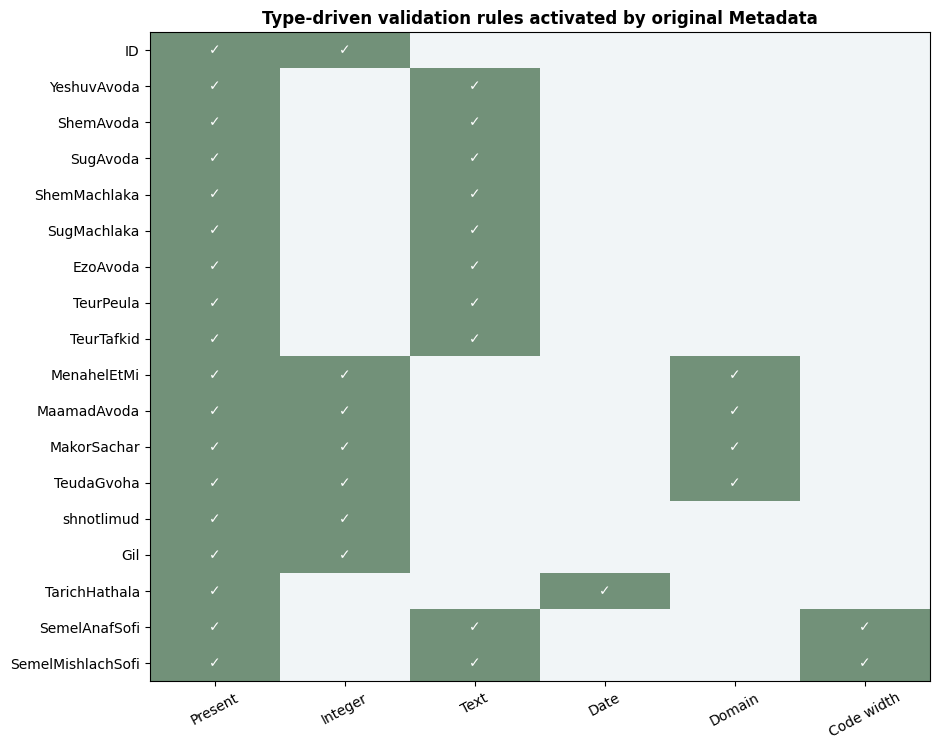

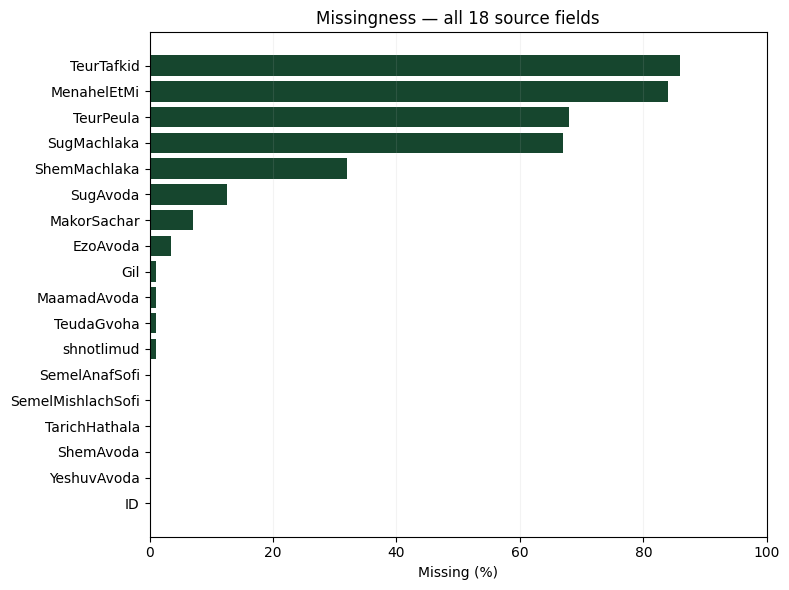

In [6]:
fig, ax = plt.subplots(figsize=(9.5,7.6))
ax.imshow(checklist.astype(int).values, aspect="auto",
          cmap=ListedColormap(["#F1F5F7",PALETTE["teal"]]), vmin=0,vmax=1)
ax.set_yticks(range(len(checklist.index)),labels=checklist.index)
ax.set_xticks(range(len(checklist.columns)),labels=["Present","Integer","Text","Date","Domain","Code width"])
ax.tick_params(axis='x', labelrotation=28)
for y in range(len(checklist.index)):
    for x in range(len(checklist.columns)):
        if checklist.iat[y,x]: ax.text(x,y,"✓",va="center",ha="center",color="white",fontsize=10)
ax.set_title("Type-driven validation rules activated by original Metadata",fontweight="bold")
fig.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(8,6.0))
ordered=summary.sort_values("missing_pct")
ax.barh(ordered["field"],ordered["missing_pct"],color=PALETTE["blue"])
ax.set(xlabel="Missing (%)",title="Missingness — all 18 source fields",xlim=(0,100))
ax.grid(axis="x",alpha=.15)
fig.tight_layout();plt.show()

## 7. תרשים מותאם-טיפוס לכל אחד מ-18 השדות
פונקציית השרטוט עצמה קוראת את הטיפוס והערכים מהמקור. `INTEGER` עם ערכים מקודדים מוצג כקטגוריות, `INTEGER` חופשי כהיסטוגרמה, `DATE` לפי שנה, `TEXT` לפי שכיחויות. אין להמיר את קודי ההשכלה לסולם מספרי רק משום שפורמט השדה הוא `INTEGER`. תוויות עבריות ארוכות מוצגות בטבלת הסבר נפרדת כדי למנוע טקסט קטוע ב-Colab בנייד.

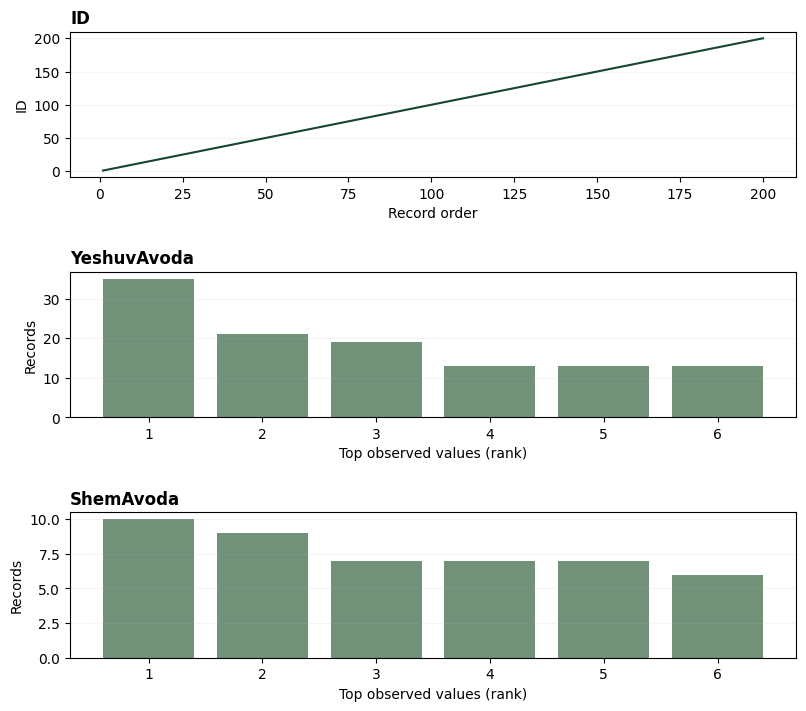

YeshuvAvoda: top observed source text: תל אביב (35) | ירושלים (21) | חיפה (19)
ShemAvoda: top observed source text: מסעדה (10) | משרד החינוך (9) | בנק לאומי (7)


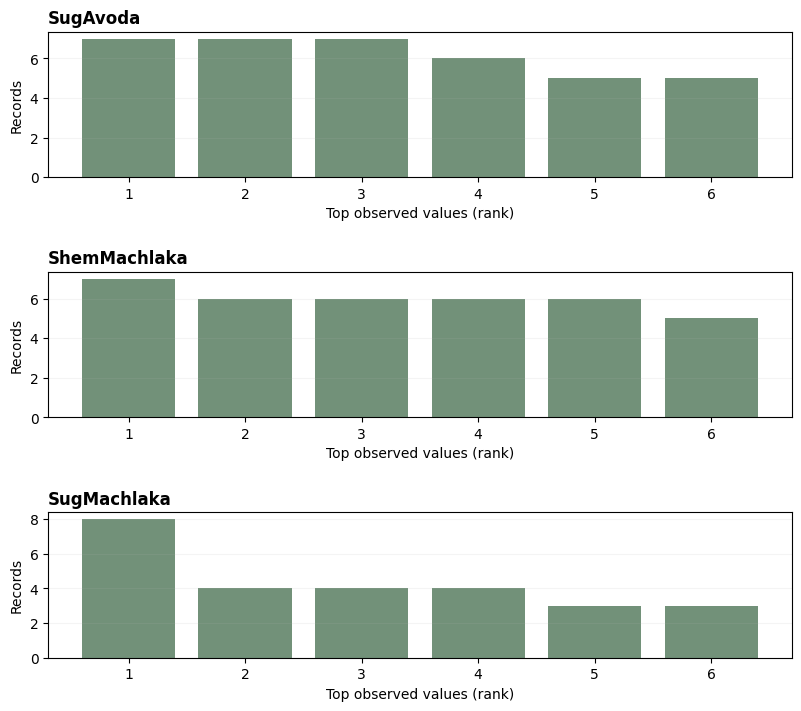

SugAvoda: top observed source text: בית ספר יסודי (7) | מסעדה (7) | חנות למכירת בגדים (7)
ShemMachlaka: top observed source text: שמירה (7) | תמיכה בלקוחות (6) | קוסמטיקה וטיפוח (6)
SugMachlaka: top observed source text: כנ"ל (8) | טיפול בחולי סרטן (4) | טיפול באנשים עם בעיות (4)


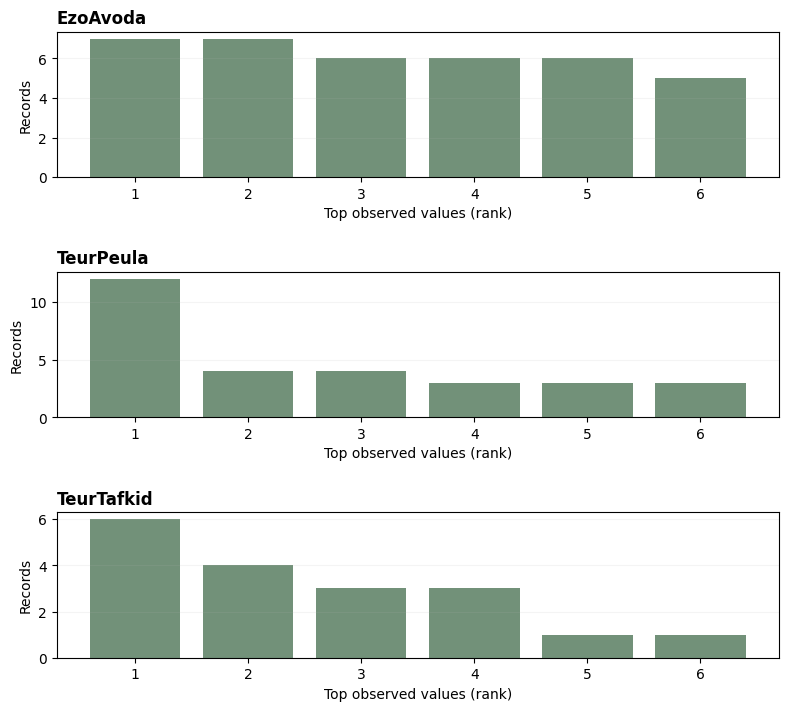

EzoAvoda: top observed source text: שומר בבית הספר (7) | טבח (7) | מנקה בית ספר אחרי הלימודים (6)
TeurPeula: top observed source text: כנ"ל (12) | מפקח על תהליך ייצור צ'יפים (4) | מסבירה לאנשים לגבי מוצרים של חברת LOREAL (4)
TeurTafkid: top observed source text: כלכלן (6) | כנ"ל (4) | סגן מנהל אגף (3)


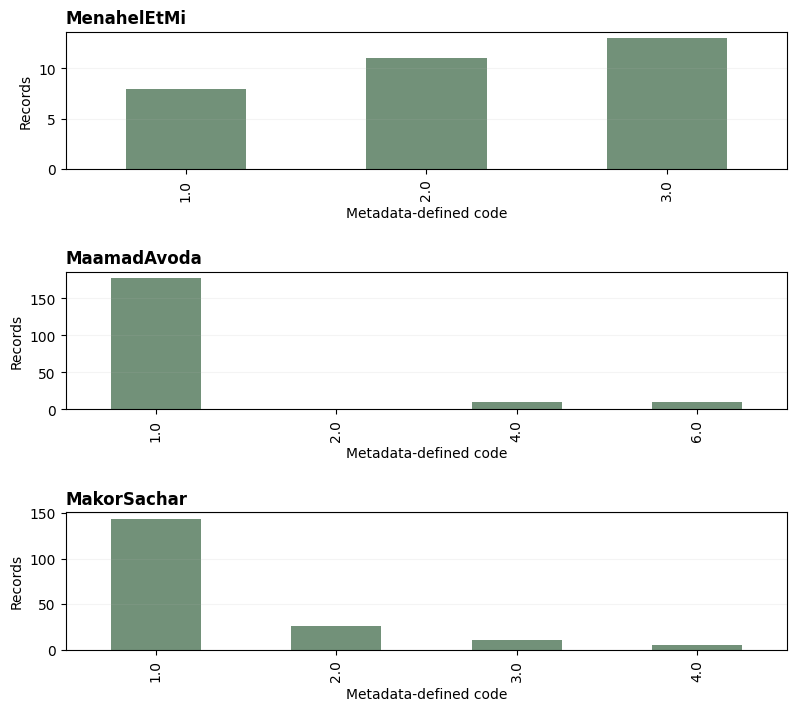

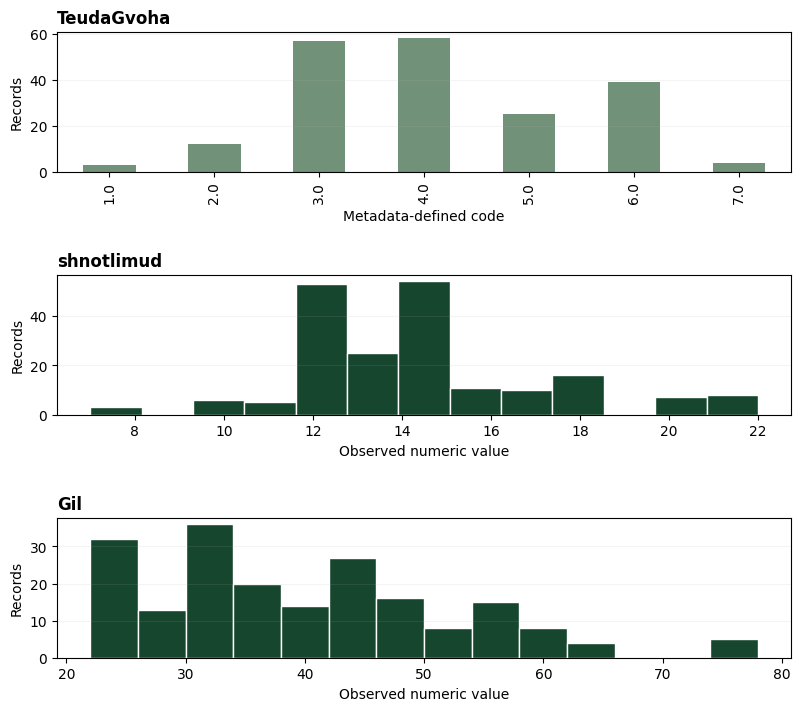

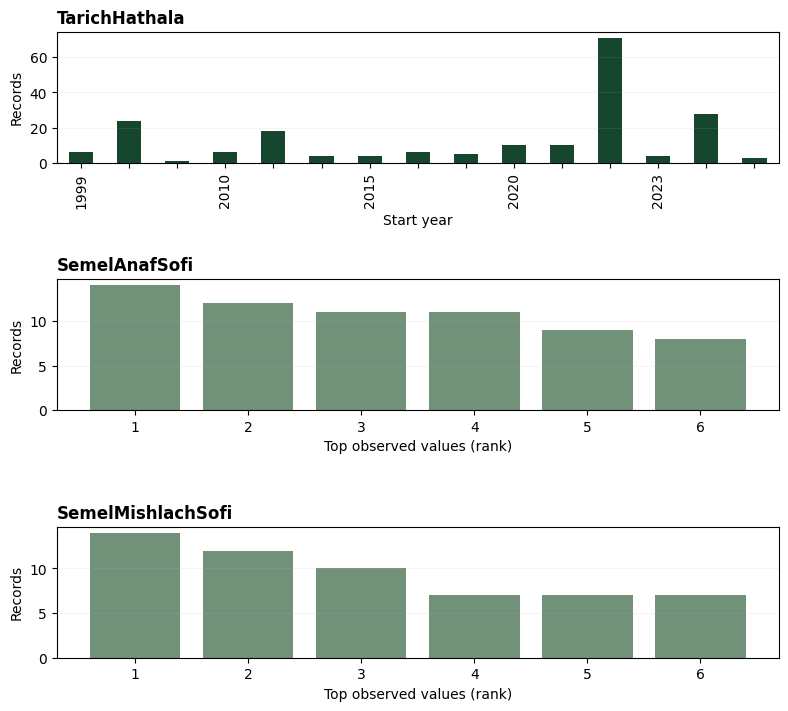

SemelAnafSofi: top observed source text: 5610 (14) | 6201 (12) | 8411 (11)
SemelMishlachSofi: top observed source text: 5223 (14) | 9112 (12) | 2512 (10)


In [7]:
def plot_from_type(field,ax):
    kind=contracts.loc[field,"פורמט"]
    s=survey[field]
    if kind=="DATE":
        yearly=pd.to_datetime(s,errors="coerce",format="mixed").dt.year.value_counts().sort_index()
        yearly.plot.bar(ax=ax,color=PALETTE["blue"])
        ax.set(xlabel="Start year",ylabel="Records")
        for n,item in enumerate(ax.get_xticklabels()):
            if n%3: item.set_visible(False)
    elif kind=="INTEGER" and enumerations[field]:
        counts=pd.to_numeric(s,errors="coerce").value_counts().sort_index()
        counts.plot.bar(ax=ax,color=PALETTE["teal"])
        ax.set(xlabel="Metadata-defined code",ylabel="Records")
    elif kind=="INTEGER" and field!="ID":
        nums=pd.to_numeric(s,errors="coerce").dropna()
        ax.hist(nums,bins=min(14,max(2,nums.nunique())),color=PALETTE["blue"],edgecolor="white")
        ax.set(xlabel="Observed numeric value",ylabel="Records")
    elif field=="ID":
        ax.plot(range(1,len(s)+1),pd.to_numeric(s),color=PALETTE["blue"])
        ax.set(xlabel="Record order",ylabel="ID")
    else:
        cleaned=s.astype("string").str.strip().replace("",pd.NA)
        counts=cleaned.value_counts().head(6)
        ax.bar(range(1,len(counts)+1),counts.values,color=PALETTE["teal"])
        ax.set_xticks(range(1,len(counts)+1))
        ax.set(xlabel="Top observed values (rank)",ylabel="Records")
    ax.set_title(field,loc="left",fontweight="bold",fontsize=12)
    ax.grid(axis="y",alpha=.13)

for start in range(0,len(survey.columns),3):
    fields=list(survey.columns[start:start+3])
    fig,axes=plt.subplots(len(fields),1,figsize=(8.4,7.5))
    for field,ax in zip(fields,np.atleast_1d(axes)):
        plot_from_type(field,ax)
    fig.tight_layout(pad=2.1)
    plt.show()
    for field in fields:
        if contracts.loc[field,"פורמט"]=="TEXT" and field!="ID":
            s=survey[field].astype("string").str.strip().replace("",pd.NA)
            observed=s.value_counts().head(3)
            print(f"{field}: top observed source text:",
                  " | ".join(f"{str(value)[:65]} ({count})" for value,count in observed.items()))

## 8. הפעלת כללים המצריכים משמעות של שדות — בנפרד מבדיקות טיפוס
בדיקות טיפוס לבדן אינן יכולות לקבוע אם שדה רלוונטי רק למעמד תעסוקה מסוים. בגיליון `Metadata` נכתב במפורש כי `MakorSachar` מלא רק עבור שכיר או חבר קואופרטיב, כפי שמוגדר ב-`MaamadAvoda`. הקודים המותרים נגזרים מהטקסט של **הערכים הממוספרים במקור**, ולא ממספרים שהוגדרו מראש בקוד.

הטענה "מלא רק כאשר ..." היא **תנאי הכרחי**, לא הוראה למלא תמיד כאשר התנאי מתקיים. לכן חוסר בשדה אצל שכיר אינו מסווג אוטומטית כהפרת חוזה. קוד סופי הכולל `X` מוגדר לפי מסמך המטלה כקוד חלקי, ולא מניחים שאפשר לשחזר אותו אוטומטית.

Applicable statuses (read from Metadata labels): {1, 5}
Salary-source conflicts: 9
Salary source with unknown status: 0
IDs of rule conflicts: [34, 49, 112, 140, 166, 176, 187, 190, 198]
Four-character target labels: 191 | target labels containing X: 9
Industry code-shape mismatches: 5
Industry X partial codes: 9


,field,rule,records
0,MakorSachar,salary_status_applicability,9
1,SemelAnafSofi,code_shape_mismatch,5


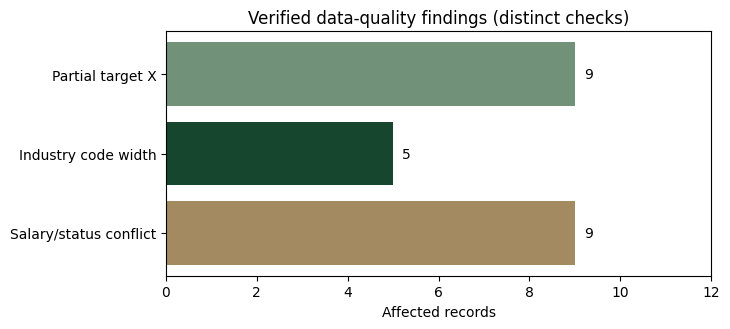

In [8]:
salary_field = metadata.loc[
    metadata["הסבר"].fillna("").str.contains("רק במידה",regex=False),"משתנה"
].tolist()
assert salary_field == ["MakorSachar"]
assert "MaamadAvoda" in str(contracts.loc["MakorSachar","הסבר"])
status_codes = enumerations["MaamadAvoda"]
salary_applicable_codes = {number for number,meaning in status_codes.items()
                           if "שכיר" in meaning or "חבר קואופרטיב" in meaning}
assert salary_applicable_codes == {1,5}, "Check the source's employment-status semantics"
status = pd.to_numeric(survey["MaamadAvoda"],errors="coerce")
salary_present = occupied(survey["MakorSachar"])
not_applicable = status.notna() & ~status.isin(salary_applicable_codes)
invalid_salary_context = not_applicable & salary_present
unknown_salary_context = status.isna() & salary_present
print("Applicable statuses (read from Metadata labels):",salary_applicable_codes)
print("Salary-source conflicts:",int(invalid_salary_context.sum()))
print("Salary source with unknown status:",int(unknown_salary_context.sum()))
print("IDs of rule conflicts:",survey.loc[invalid_salary_context,"ID"].astype(int).tolist())
assert invalid_salary_context.sum()==9
assert not unknown_salary_context.any()

industry_flags=validate_type(survey,"SemelAnafSofi")
target_flags=validate_type(survey,TARGET)
complete_mask = occupied(survey[TARGET]) & ~target_flags["partial_X_code"] & ~target_flags["code_shape_mismatch"]
partial_mask = target_flags["partial_X_code"]
assert int(complete_mask.sum())==191 and int(partial_mask.sum())==9
print("Four-character target labels:",int(complete_mask.sum()),
      "| target labels containing X:",int(partial_mask.sum()))
print("Industry code-shape mismatches:",int(industry_flags["code_shape_mismatch"].sum()))
print("Industry X partial codes:",int(industry_flags["partial_X_code"].sum()))

cross_issues=pd.DataFrame({"ID":survey.loc[invalid_salary_context,"ID"].astype(int),
                           "field":"MakorSachar","rule":"salary_status_applicability",
                           "source":"Metadata description and MaamadAvoda enumerated labels"})
issue_totals=(pd.concat([issues[["ID","field","rule"]],cross_issues[["ID","field","rule"]]],
                       ignore_index=True)
                .groupby(["field","rule"]).size().rename("records").reset_index())
display(issue_totals)

fig,ax=plt.subplots(figsize=(7.4,3.4))
keys=["Partial target X","Industry code width","Salary/status conflict"]
vals=[int(partial_mask.sum()),int(industry_flags["code_shape_mismatch"].sum()),int(invalid_salary_context.sum())]
ax.barh(keys[::-1],vals[::-1],color=[PALETTE["orange"],PALETTE["blue"],PALETTE["teal"]])
ax.set(xlabel="Affected records",title="Verified data-quality findings (distinct checks)")
for i,value in enumerate(vals[::-1]):ax.text(value+.2,i,str(value),va="center")
ax.set_xlim(0,max(vals)+3)
fig.tight_layout();plt.show()

## 9. כפילויות ותוויות סותרות
המסמך מתאר שידורים חוזרים. אולם `ID` הוא "מספר רץ" לפי Metadata ואינו מזהה משתתף יציב, ואין תאריך שידור. לפיכך אי אפשר להסיק שמספר שורות שייכות לאותו אדם. כתחליף מוגבל נבנית חתימה של שבעה שדות תיאור, המשמשת רק לבדיקת דמיון ולחלוקת אימון/בדיקה מופרדת קבוצות. כל שינוי בתיאורי הסקר עלול ליצור קבוצה חדשה גם אם מדובר באותו משתתף.

In [9]:
assert pd.to_numeric(survey["ID"],errors="coerce").is_unique
GROUP_FIELDS=["ShemAvoda","SugAvoda","ShemMachlaka","SugMachlaka",
              "EzoAvoda","TeurPeula","TeurTafkid"]
def normal_signature(x):
    if pd.isna(x): return ""
    return " ".join(re.sub(r"[^\w\u0590-\u05ff]+"," ",str(x).lower()).split())
groups=survey[GROUP_FIELDS].apply(
    lambda row:"|".join(normal_signature(row[k]) for k in GROUP_FIELDS),axis=1)
clusters=(survey.assign(group_signature=groups)
          .groupby("group_signature",dropna=False)
          .agg(records=("ID","size"),distinct_target_labels=(TARGET,"nunique")))
print("Description groups:",len(clusters),
      "| groups repeated:",int(clusters.records.gt(1).sum()),
      "| conflicting-label groups:",int(clusters.distinct_target_labels.gt(1).sum()))
conflict_keys=set(clusters.index[clusters.distinct_target_labels.gt(1)])
display(survey.loc[groups.isin(conflict_keys),["ID","ShemAvoda","EzoAvoda",TARGET]])

Description groups: 137 | groups repeated: 40 | conflicting-label groups: 1


,ID,ShemAvoda,EzoAvoda,SemelMishlachSofi
1,2.0,בית חולים הדסה עין כרם,טכנאית רדיותרפיה,3311
32,33.0,בית חולים הדסה עין כרם,טכנאית רדיותרפיה,3211
64,65.0,בית חולים הדסה עין כרם,טכנאית רדיותרפיה,3211
95,96.0,בית חולים הדסה עין כרם,טכנאית רדיותרפיה,3211


## 10. אישור החלטות על תכונות — מבוסס סוג, אך אינו מוכתב רק ממנו
**הפרדת תחומי אחריות:** `TEXT` מפעיל בדיקות טקסט אבל אינו אומר שכל טקסט צריך להיכלל במודל; `INTEGER` עם ערכים ממוספרים הוא *משתנה קטגוריאלי* ולא ערך רציף. זמינות השדה בזמן אמת והסיכון לזליגה נקבעים לפי משמעותו ותהליך הסימול.

המודל משתמש בשישה תיאורי עבודה, בארבעה שדות עם קודים ממוספרים ובשנות לימוד. `ID` הוא זיהוי בלבד; שם המעסיק והיישוב נשארים לצורכי ביקורת וקיבוץ; גיל ותאריך התחלה מוצגים אך אינם תכונות במודל הבסיסי; `SemelAnafSofi` מוחרג כי זמינות הסמל הענפי הסופי לפני סיווג משלח היד אינה מוכחת; היעד לעולם אינו נכלל בתכונות. זו **מדיניות אנליטית מפורשת**, לא תוכן שהמצאנו ל-Metadata.

In [10]:
APPROVED_TEXT=["SugAvoda","ShemMachlaka","SugMachlaka",
               "EzoAvoda","TeurPeula","TeurTafkid"]
APPROVED_CATEGORICAL=["MenahelEtMi","MaamadAvoda","MakorSachar","TeudaGvoha"]
APPROVED_NUMERIC=["shnotlimud"]
FEATURES=APPROVED_TEXT+APPROVED_CATEGORICAL+APPROVED_NUMERIC
EXCLUDED=[name for name in survey.columns if name not in FEATURES]
assert len(FEATURES)==11 and len(EXCLUDED)==7
assert all(contracts.loc[name,"פורמט"]=="TEXT" and not widths[name] for name in APPROVED_TEXT)
assert all(contracts.loc[name,"פורמט"]=="INTEGER" and bool(enumerations[name])
           for name in APPROVED_CATEGORICAL)
assert all(contracts.loc[name,"פורמט"]=="INTEGER" and not enumerations[name]
           for name in APPROVED_NUMERIC)
assert TARGET in EXCLUDED and "SemelAnafSofi" in EXCLUDED

for name in survey.columns:
    role=("TEXT_SIX_REPRESENTATIONS" if name in APPROVED_TEXT else
          "NOMINAL_ONE_HOT" if name in APPROVED_CATEGORICAL else
          "NUMERIC_IMPUTE_SCALE" if name in APPROVED_NUMERIC else
          "TARGET_NOT_FEATURE" if name==TARGET else
          "AUDIT_AND_GROUP_ONLY" if name=="ShemAvoda" else
          "AUDIT_EXCLUDED")
    r=summary.loc[summary.field.eq(name)].iloc[0]
    print(f"{name:20} Metadata={r['type']:7} Role={role:22} "
          f"Missing={r['missing']:3} Type issues={r['violations']:2}")

ID                   Metadata=INTEGER Role=AUDIT_EXCLUDED         Missing=  0 Type issues= 0
YeshuvAvoda          Metadata=TEXT    Role=AUDIT_EXCLUDED         Missing=  0 Type issues= 0
ShemAvoda            Metadata=TEXT    Role=AUDIT_AND_GROUP_ONLY   Missing=  0 Type issues= 0
SugAvoda             Metadata=TEXT    Role=TEXT_SIX_REPRESENTATIONS Missing= 25 Type issues= 0
ShemMachlaka         Metadata=TEXT    Role=TEXT_SIX_REPRESENTATIONS Missing= 64 Type issues= 0
SugMachlaka          Metadata=TEXT    Role=TEXT_SIX_REPRESENTATIONS Missing=134 Type issues= 0
EzoAvoda             Metadata=TEXT    Role=TEXT_SIX_REPRESENTATIONS Missing=  7 Type issues= 0
TeurPeula            Metadata=TEXT    Role=TEXT_SIX_REPRESENTATIONS Missing=136 Type issues= 0
TeurTafkid           Metadata=TEXT    Role=TEXT_SIX_REPRESENTATIONS Missing=172 Type issues= 0
MenahelEtMi          Metadata=INTEGER Role=NOMINAL_ONE_HOT        Missing=168 Type issues= 0
MaamadAvoda          Metadata=INTEGER Role=NOMINAL_ONE_HOT

## 11. פירוק בעיית הייצוג — שש חלופות ללא שינוי באלגוריתם הסיווג

הבחנה חשובה: TF-IDF הוא וקטור משוקלל של תכונות לקסיקליות; נרמול L2 מבטיח אורך 1 ומאפשר לפרש מכפלות פנימיות כדמיון קוסינוס, אך **אינו מחשב בפועל מרחקים בין רשומות**. כדי לבחון במפורש ייצוג מרחק אוקלידי, שיטות 3–4 מייצרות *מרחקים אוקלידיים לעוגני תיאור שנלמדו מאימון בלבד*. זהו ייצוג תכונות שונה, בלי לשנות את המסווג.

- **One-Hot text:** כל ערך טקסט נצפה הוא קטגוריה עצמאית; אינו מקודד דמיון בין ערכים.
- **Direct TF-IDF:** נרמול L2 והחלקת IDF פעילה; אין שכבת מרחקים נפרדת.
- **Euclidean TF-IDF:** מרחקים לעוגנים ייחודיים מתוך האימון, בשתי אפשרויות `smooth_idf`.
- **CH clusters:** התאמת KMeans לכל עמודת תיאור בנפרד על ערכים ייחודיים; בחירת K לפי מקסימום Calinski–Harabasz, ולאחר מכן OneHotEncoder על מזהי האשכולות.

**תנאי השוואה זהים:** שש עמודות תיאור, ארבע עמודות קוד נומינליות, שנות לימוד כמותיות, אותו `LogisticRegression(C=1.0)`, אותה חלוקה מקובצת, אותו כלל לניקוי חסר ותיאור בלתי-אינפורמטיבי. אין תוויות יעד בסקר הקריטריון CH.

In [11]:
# Consistent field-level preprocessing for every candidate.
NO_SIGNAL_TEXT={'כנ"ל','כנ״ל','חסוי','לא יכול לפרט','0'}

def model_features(frame):
    df=pd.DataFrame(index=frame.index)
    for f in APPROVED_TEXT:
        val=(frame[f].astype('string').fillna('')
             .str.replace(r'\s+',' ',regex=True).str.strip())
        df[f]=val.mask(val.isin(NO_SIGNAL_TEXT),'').astype(str)
    for f in APPROVED_CATEGORICAL:
        val=pd.to_numeric(frame[f],errors='coerce').astype('Int64')
        df[f]=val.astype('string').fillna('MISSING').astype(str)
    status=pd.to_numeric(frame['MaamadAvoda'],errors='coerce')
    eligible=status.isin(salary_applicable_codes)
    unknown=status.isna()
    df.loc[~eligible & ~unknown,'MakorSachar']='NOT_APPLICABLE'
    df.loc[unknown,'MakorSachar']='APPLICABILITY_UNKNOWN'
    for f in APPROVED_NUMERIC:
        df[f]=pd.to_numeric(frame[f],errors='coerce')
    assert df[FEATURES].columns.tolist()==FEATURES
    return df[FEATURES]

complete_mask=~partial_mask
complete=survey.loc[complete_mask].copy()
partial=survey.loc[partial_mask].copy()
X=model_features(complete)
y=complete[TARGET].astype(str)
group_ids=groups.loc[complete.index]
assert len(complete)==191 and len(partial)==9
splitter=GroupShuffleSplit(n_splits=1,test_size=.22,random_state=SEED)
train_idx,test_idx=next(splitter.split(X,y,groups=group_ids))
X_train,X_test=X.iloc[train_idx],X.iloc[test_idx]
y_train,y_test=y.iloc[train_idx],y.iloc[test_idx]
g_train=group_ids.iloc[train_idx]
assert set(g_train).isdisjoint(set(group_ids.iloc[test_idx]))
assert TARGET not in X.columns and 'SemelAnafSofi' not in X.columns
print('Training records:',len(X_train),'| Frozen external holdout:',len(X_test))
print('Target classes in training:',y_train.nunique(), '| Holdout labels never seen in training:',(~y_test.isin(set(y_train))).sum())

Training records: 149 | Frozen external holdout: 42
Target classes in training: 52 | Holdout labels never seen in training: 8


## 12. מימוש ייצוגי טקסט — Transformer שמותאם באימון בלבד

- **עוגני המרחק:** כל ערך טקסט ייחודי שנצפה באימון משמש עוגן. מרחקים למכלול העוגנים מחושבים באמצעות `euclidean_distances`. אין מידע מקבוצת הבדיקה בשלב בחירת העוגנים.
- **אשכולות:** לכל שדה בנפרד נסרק הטווח **המלא** `2..min(100,20,⌊2u/3⌋,u-1)` כאשר `u` הוא מספר הווקטורים הייחודיים באימון. הגבלת 20 מצמצמת עלות וזמני ריצה. כל K שנבחן נרשם ומוצג. המספר המירבי 100 הוא תקרה, לא יעד שנדרש להשיג.
- **בחירת K:** ניקוד CH הגבוה ביותר לאחר עיגול לשתי ספרות; כאשר הניקודים קטנים, משתמשים ביותר ספרות באופן דטרמיניסטי. בתיקו בוחרים K נמוך. לא בוחרים K לפי תוויות היעד.
- **בדיקת נכונות:** כלל CH אינו מבחן F להסקה סטטיסטית ואינו מבטיח זהות סמנטית. נבחן גם את תוכן האשכולות בפועל.

In [12]:
TFIDF_OPTIONS={'analyzer':'char','ngram_range':(2,4),'norm':'l2',
               'sublinear_tf':True,'max_features':1200}
MAX_K=20
MAX_K_HARD=100
K_RATIO=2/3


def tfidf(smooth):
    return TfidfVectorizer(**TFIDF_OPTIONS,smooth_idf=bool(smooth))


def precision_for_ch(scores):
    finite=np.asarray([float(s) for s in scores if np.isfinite(s)],dtype=float)
    if finite.size==0 or np.max(np.abs(finite))==0:
        return 8
    mx=float(np.max(np.abs(finite)))
    return 2 if mx>=1 else min(9,max(2,2-int(np.floor(np.log10(mx)))))


def best_ch_k(scores):
    valid=[(int(k),float(score)) for k,score in scores if np.isfinite(score)]
    if not valid: return None
    digits=precision_for_ch([s for _,s in valid])
    return sorted(valid,key=lambda item:(-round(item[1],digits),item[0]))[0] + (digits,)

assert best_ch_k([(2,19.113),(4,19.114)])[0]==2
assert best_ch_k([(2,.000100),(4,.000120)])[0]==4


def as_text_array(X):
    if isinstance(X,pd.Series):
        return X.fillna('').astype(str).tolist()
    if isinstance(X,pd.DataFrame):
        return X.iloc[:,0].fillna('').astype(str).tolist()
    arr=np.asarray(X,dtype=object)
    return pd.Series(arr.ravel()).fillna('').astype(str).tolist()


class EuclideanToTrainingText(BaseEstimator,TransformerMixin):
    """Distances to every distinct training-only TF-IDF reference text."""
    def __init__(self,smooth_idf=True,max_features=1200):
        self.smooth_idf=smooth_idf;self.max_features=max_features

    def fit(self,X,y=None):
        values=as_text_array(X)
        self.references_=sorted(set(values))
        self.encoder_=TfidfVectorizer(analyzer='char',ngram_range=(2,4),norm='l2',
                                     max_features=self.max_features,
                                     sublinear_tf=True,smooth_idf=self.smooth_idf)
        # A field entirely missing in a fold must remain valid.
        if not any(v.strip() for v in values):
            self.all_missing_=True
            return self
        self.all_missing_=False
        self.encoder_.fit(values)
        self.anchor_vectors_=self.encoder_.transform(self.references_)
        return self

    def transform(self,X):
        vals=as_text_array(X)
        if self.all_missing_:
            return np.zeros((len(vals),1))
        mat=self.encoder_.transform(vals)
        distances=euclidean_distances(mat,self.anchor_vectors_)
        assert distances.shape==(len(vals),len(self.references_))
        return distances


class CHSelectedTextClusters(BaseEstimator,TransformerMixin):
    """Train-only, separate K-means/CH search for every original text field."""
    def __init__(self,fields,smooth_idf=True,max_k=MAX_K,hard_max=MAX_K_HARD,
                 ratio=K_RATIO,max_features=900,n_init=3,max_iter=130,random_state=SEED):
        self.fields=fields;self.smooth_idf=smooth_idf;self.max_k=max_k
        self.hard_max=hard_max;self.ratio=ratio;self.max_features=max_features
        self.n_init=n_init;self.max_iter=max_iter;self.random_state=random_state

    def fit(self,X,y=None):
        frame=pd.DataFrame(X,columns=self.fields)
        self.models_={};self.scores_=[];self.selection_=[]
        for field in self.fields:
            unique=sorted(v for v in frame[field].fillna('').astype(str).unique() if v.strip())
            entry={'kind':'fallback','lookup':{},'chosen_k':None,'field':field,
                   'distinct_texts':len(unique)}
            if len(unique)>=3:
                vectorizer=TfidfVectorizer(analyzer='char',ngram_range=(2,4),
                                           norm='l2',max_features=self.max_features,
                                           sublinear_tf=True,smooth_idf=self.smooth_idf)
                vectors=vectorizer.fit_transform(unique).toarray()
                distinct=int(np.unique(np.round(vectors,12),axis=0).shape[0])
                cap=min(self.hard_max,self.max_k,int(np.floor(self.ratio*distinct)),
                        distinct-1,len(unique)-1)
                if cap>=2:
                    scorepairs=[];candidate_models={}
                    for k in range(2,cap+1):
                        km=KMeans(n_clusters=k,n_init=self.n_init,max_iter=self.max_iter,
                                  random_state=self.random_state,algorithm='lloyd')
                        labels=km.fit_predict(vectors)
                        valid=(2<=np.unique(labels).size<len(unique))
                        ch=float(calinski_harabasz_score(vectors,labels)) if valid else np.nan
                        self.scores_.append({'field':field,'smoothing':self.smooth_idf,
                                             'k':k,'ch':ch,'valid':bool(np.isfinite(ch))})
                        if np.isfinite(ch):scorepairs.append((k,ch));candidate_models[k]=km
                    choice=best_ch_k(scorepairs)
                    if choice:
                        k,ch,digits=choice
                        km=candidate_models[k]
                        entry.update(kind='kmeans',vectorizer=vectorizer,kmeans=km,
                                     chosen_k=k,ch=ch,precision=digits,
                                     lookup={v:f'cluster_{lab:03d}' for v,lab in zip(unique,km.labels_)})
            if entry['kind']=='fallback':
                entry['lookup']={v:f'value_{i:03d}' for i,v in enumerate(unique)}
            self.models_[field]=entry
            self.selection_.append({'field':field,'smoothing':self.smooth_idf,
                                    'n_distinct_values':len(unique),
                                    'chosen_k':entry['chosen_k'],
                                    'ch_score':entry.get('ch',np.nan),
                                    'status':entry['kind']})
        self.score_table_=pd.DataFrame(self.scores_,columns=['field','smoothing','k','ch','valid'])
        self.selection_table_=pd.DataFrame(self.selection_)
        return self

    def transform(self,X):
        if not hasattr(self,'models_'):raise ValueError('fit() must precede transform()')
        frame=pd.DataFrame(X,columns=self.fields)
        out=np.empty((len(frame),len(self.fields)),dtype=object)
        for j,field in enumerate(self.fields):
            e=self.models_[field]
            values=frame[field].fillna('').astype(str).tolist()
            assigned=[]
            for v in values:
                if not v.strip():assigned.append('MISSING')
                elif v in e['lookup']:assigned.append(e['lookup'][v])
                elif e['kind']=='kmeans':
                    lab=int(e['kmeans'].predict(e['vectorizer'].transform([v]))[0])
                    assigned.append(f'cluster_{lab:03d}')
                else:assigned.append('UNSEEN_VALUE')
            out[:,j]=assigned
        return out

    def get_feature_names_out(self,input_features=None):
        return np.asarray(self.fields,dtype=object)

# Verify the literal nominal encoding: no integer ordering is ever supplied.
probe=pd.DataFrame({'field':['software','software','maintenance']})
encoder=EuclideanToTrainingText(smooth_idf=True).fit(probe[['field']])
assert encoder.transform(probe[['field']]).shape[1]==2
print('Distance prototypes are derived from training values only.')

Distance prototypes are derived from training values only.


## 13. שישה צינורות אימון — אותו מסווג ואותם משתנים שאינם טקסט

כל החלופות נוצרות מאותה פונקציה; ההבדל היחיד הוא מסלול העיבוד של ששת שדות הטקסט. ערכי `MakorSachar` נבדקים בהקשר `MaamadAvoda`. תכונות הטקסט אינן כוללות `SemelAnafSofi`, מזהי רשומות או תוויות מטרה.

**הכרעה מדעית:** נבחר דגם על פי `macro_f1` הממוצע בפיצולי אימות פנימיים **לפני** הסתכלות בקבוצת הבדיקה החיצונית. במקרה של תיקו משלבים `macro_recall` ואז פשטות המבנה. המדדים החיצוניים של שש החלופות ניתנים לצורך שקיפות, ואינם משמשים לבחירת הדגם.

In [13]:
VARIANTS=[
 ('onehot','One-hot: complete texts',None),
 ('tfidf','Direct TF-IDF · smooth',True),
 ('euclidean','Euclidean TF-IDF · smooth',True),
 ('euclidean','Euclidean TF-IDF · no smooth',False),
 ('clusters','CH clusters → one-hot · smooth',True),
 ('clusters','CH clusters → one-hot · no smooth',False),
]

def variant_name(kind,smooth):
    return next(name for k,name,s in VARIANTS if kind==k and smooth==s)


def build_candidate(kind,smooth=None):
    if kind=='onehot':
        text_transformers=[('text_labels',OneHotEncoder(handle_unknown='ignore'),
                            APPROVED_TEXT)]
    elif kind=='tfidf':
        text_transformers=[(f'text_{field}',tfidf(smooth),field)
                            for field in APPROVED_TEXT]
    elif kind=='euclidean':
        text_transformers=[(f'dist_{field}',EuclideanToTrainingText(
                              smooth_idf=smooth),field) for field in APPROVED_TEXT]
    elif kind=='clusters':
        cluster=Pipeline([
            ('assign',CHSelectedTextClusters(tuple(APPROVED_TEXT),smooth_idf=smooth)),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ])
        text_transformers=[('cluster_text',cluster,APPROVED_TEXT)]
    else:raise ValueError(f'Unknown representation: {kind}')
    preprocessor=ColumnTransformer([
        *text_transformers,
        ('nominal',OneHotEncoder(handle_unknown='ignore'),APPROVED_CATEGORICAL),
        ('numeric',Pipeline([('impute',SimpleImputer(strategy='median')),
                             ('scale',StandardScaler())]),APPROVED_NUMERIC)
    ],remainder='drop',sparse_threshold=1.0)
    return Pipeline([
        ('represent',preprocessor),
        ('classifier',LogisticRegression(C=1.,max_iter=1200,solver='lbfgs',
                                         random_state=SEED))
    ])

# Local sanity test confirms six distinct representations and exact estimator parity.
candidates={name:build_candidate(kind,smooth) for kind,name,smooth in VARIANTS}
assert len(candidates)==6
assert {type(p.named_steps['classifier']).__name__ for p in candidates.values()}=={'LogisticRegression'}
print('Comparable configurations:',len(candidates))
for name in candidates:print(' •',name)

Comparable configurations: 6
 • One-hot: complete texts
 • Direct TF-IDF · smooth
 • Euclidean TF-IDF · smooth
 • Euclidean TF-IDF · no smooth
 • CH clusters → one-hot · smooth
 • CH clusters → one-hot · no smooth


## 14. בחירת החלופה על אימון בלבד — אימות פנימי לפי קבוצות

- כל חלופה נבחנת על **אותם שלושה פיצולי אימות פנימיים** מתוך אימון-החוץ בלבד. מאפייני הטקסט, TF-IDF, אבות-המרחק, ה-CH, המקודדים ומקדמי המסווג כולם נלמדים מחדש בכל פיצול אימון פנימי.
- מתייחסים לכל תוויות משלח היד כקודים נומינליים ולא מדרגים מספריים.
- מחלקות חסרות באימון אינן ניתנות לחיזוי ולכן מדווחות במפורש. `macro_F1` הוא ממוצע F1 שאינו משוקלל לפי גודל המחלקה; `macro_recall` הוא ממוצע recall על המחלקות, עם אפס היכן שלא התקבל חיזוי.
- ההערכה הפנימית משמשת להכרעה מתודולוגית בלבד; אין לטעון שהפרש קטן ובלתי-מובהק בדוגמת דמה מוכיח יתרון תפעולי.

In [14]:
def classification_metrics(y_true,y_pred):
    return {'accuracy':accuracy_score(y_true,y_pred),
            'macro_precision':precision_score(y_true,y_pred,average='macro',zero_division=0),
            'macro_recall':recall_score(y_true,y_pred,average='macro',zero_division=0),
            'macro_f1':f1_score(y_true,y_pred,average='macro',zero_division=0),
            'weighted_recall':recall_score(y_true,y_pred,average='weighted',zero_division=0),
            'weighted_f1':f1_score(y_true,y_pred,average='weighted',zero_division=0)}

inner=GroupShuffleSplit(n_splits=3,test_size=.24,random_state=SEED+10)
inner_splits=list(inner.split(X_train,y_train,groups=g_train))
inner_records=[]
for split_i,(a,b) in enumerate(inner_splits,start=1):
    assert set(g_train.iloc[a]).isdisjoint(set(g_train.iloc[b]))
    for kind,label,smoothing in VARIANTS:
        t0=perf_counter()
        candidate=build_candidate(kind,smoothing)
        candidate.fit(X_train.iloc[a],y_train.iloc[a])
        pred=candidate.predict(X_train.iloc[b])
        row={'split':split_i,'model':label,'family':kind,'smooth_idf':smoothing,
             'train_rows':len(a),'valid_rows':len(b),
             'unseen_label_rows':int((~y_train.iloc[b].isin(set(y_train.iloc[a]))).sum()),
             'fit_sec':perf_counter()-t0}
        row.update(classification_metrics(y_train.iloc[b],pred))
        inner_records.append(row)
inner_results=pd.DataFrame(inner_records)
inner_summary=(inner_results.groupby('model',as_index=False)
    .agg(macro_f1_mean=('macro_f1','mean'),macro_f1_sd=('macro_f1','std'),
         macro_recall_mean=('macro_recall','mean'),weighted_f1_mean=('weighted_f1','mean'),
         accuracy_mean=('accuracy','mean'),runtime_sec=('fit_sec','sum')))
# Primary metric was fixed before viewing the external holdout.
priority={name:i for i,(_,name,_) in enumerate(VARIANTS)}
inner_summary['complexity_order']=inner_summary.model.map(priority)
inner_summary=inner_summary.sort_values(['macro_f1_mean','macro_recall_mean','complexity_order'],
    ascending=[False,False,True]).reset_index(drop=True)
SELECTED=inner_summary.loc[0,'model']
print('Selected by internal validation:',SELECTED)
display(inner_summary.round(4))
print('Individual validation splits:')
display(inner_results[['split','model','valid_rows','unseen_label_rows',
                       'macro_f1','macro_recall','weighted_f1','accuracy']].round(3))

Selected by internal validation: Direct TF-IDF · smooth


,model,macro_f1_mean,macro_f1_sd,macro_recall_mean,weighted_f1_mean,accuracy_mean,runtime_sec,complexity_order
0,Direct TF-IDF · smooth,0.4801,0.0322,0.5001,0.6347,0.6410,1.2012,1
1,CH clusters → one-hot · no smooth,0.4732,0.0622,0.5032,0.6088,0.6325,1.0763,5
2,Euclidean TF-IDF · smooth,0.4419,0.0548,0.4771,0.5846,0.6138,0.7529,2
3,Euclidean TF-IDF · no smooth,0.4419,0.0548,0.4771,0.5846,0.6138,0.7991,3
4,CH clusters → one-hot · smooth,0.4280,0.0558,0.4632,0.5904,0.6138,1.1427,4
5,One-hot: complete texts,0.3722,0.0169,0.3903,0.5363,0.5462,0.1345,0


Individual validation splits:


,split,model,valid_rows,unseen_label_rows,macro_f1,macro_recall,weighted_f1,accuracy
0,1,One-hot: complete texts,33,9,0.389,0.380,0.560,0.545
1,1,Direct TF-IDF · smooth,33,9,0.472,0.458,0.626,0.606
2,1,Euclidean TF-IDF · smooth,33,9,0.447,0.455,0.566,0.576
3,1,Euclidean TF-IDF · no smooth,33,9,0.447,0.455,0.566,0.576
4,1,CH clusters → one-hot · smooth,33,9,0.436,0.438,0.604,0.606
5,1,CH clusters → one-hot · no smooth,33,9,0.467,0.477,0.592,0.606
6,2,One-hot: complete texts,39,12,0.356,0.383,0.470,0.487
7,2,Direct TF-IDF · smooth,39,12,0.452,0.500,0.550,0.590
8,2,Euclidean TF-IDF · smooth,39,12,0.385,0.446,0.477,0.538
9,2,Euclidean TF-IDF · no smooth,39,12,0.385,0.446,0.477,0.538


## 15. השוואה חיצונית אחת — ששת המודלים על אותה קבוצת בדיקה

לאחר קיבוע הבחירה מאמנים מחדש כל חלופה על **כל אימון-החוץ**, ואז מעריכים אותן על קבוצת הבדיקה ששמרנו קודם. כל שש השורות מדווחות גם אם מסווג אחר זוכה במדד בודד. התוצאה של המסווג שנבחר מראש היא תוצאת ההגשה המועדפת; יתר השורות מאפשרות להבין את השפעת בחירת הייצוג, בלי להעמיד פנים שמדובר בהתקדמות מונוטונית.

In [15]:
outer_models={};outer_predictions={};outer_rows=[]
for kind,name,smoothing in VARIANTS:
    candidate=build_candidate(kind,smoothing)
    start=perf_counter()
    candidate.fit(X_train,y_train)
    prediction=candidate.predict(X_test)
    represented=candidate.named_steps['represent'].transform(X_train)
    data={'model':name,'family':kind,'smooth_idf':smoothing,
          'n_features':represented.shape[1],'fit_sec':perf_counter()-start,
          'correct':int(np.sum(prediction==y_test.to_numpy()))}
    data.update(classification_metrics(y_test,prediction))
    outer_rows.append(data)
    outer_models[name]=candidate
    outer_predictions[name]=prediction
external=pd.DataFrame(outer_rows)
assert len(external)==len(VARIANTS)
assert all(np.isclose(external.weighted_recall,external.accuracy))
print('FROZEN HOLDOUT: ',len(X_test),'records /',int((~y_test.isin(set(y_train))).sum()),'unseen-label records')
print('INTERNALLY SELECTED MODEL:',SELECTED)
display(external[['model','n_features','correct','accuracy','macro_recall','macro_f1',
                  'weighted_f1','fit_sec']].round(4))

held_out=pd.DataFrame({'ID':complete.iloc[test_idx]['ID'].astype(int).to_numpy(),
                       'given_code':y_test.to_numpy(),
                       'class_seen_in_training':y_test.isin(set(y_train)).to_numpy(),
                       **{name:pred for name,pred in outer_predictions.items()}})
# Model-level contract: novel descriptions must be representable without refitting.
novel=X_test.iloc[:2].copy()
for f in APPROVED_TEXT:
    novel[f]='UNSEEN_OCCUPATIONAL_DESCRIPTION_'+f
for model_name,pipeline in outer_models.items():
    unseen_output=pipeline.predict(novel)
    assert unseen_output.shape==(2,),model_name
print('Every candidate predicts unseen descriptions without refitting: PASS')
print('Every held-out prediction for every representation:')
for start in range(0,len(held_out),14):
    display(held_out.iloc[start:start+14].reset_index(drop=True))

FROZEN HOLDOUT:  42 records / 8 unseen-label records
INTERNALLY SELECTED MODEL: Direct TF-IDF · smooth


,model,n_features,correct,accuracy,macro_recall,macro_f1,weighted_f1,fit_sec
0,One-hot: complete texts,269,30,0.7143,0.5309,0.5033,0.6954,0.0607
1,Direct TF-IDF · smooth,4503,31,0.7381,0.5185,0.4879,0.6973,0.4616
2,Euclidean TF-IDF · smooth,269,30,0.7143,0.5062,0.4808,0.6662,0.4018
3,Euclidean TF-IDF · no smooth,269,30,0.7143,0.5062,0.4808,0.6662,0.4050
4,CH clusters → one-hot · smooth,75,28,0.6667,0.4086,0.4047,0.6452,0.4167
5,CH clusters → one-hot · no smooth,114,31,0.7381,0.5432,0.5112,0.7000,0.4011


Every candidate predicts unseen descriptions without refitting: PASS
Every held-out prediction for every representation:


,ID,given_code,class_seen_in_training,One-hot: complete texts,Direct TF-IDF · smooth,Euclidean TF-IDF · smooth,Euclidean TF-IDF · no smooth,CH clusters → one-hot · smooth,CH clusters → one-hot · no smooth
0,12,2631,True,2631,2631,2631,2631,2631,2631
1,13,5131,True,5131,5131,5131,5131,5223,5131
2,16,5223,True,5223,5223,5223,5223,5223,5223
3,25,3323,False,4313,5322,5223,5223,2655,2142
4,27,9112,True,9112,9112,9112,9112,9112,9112
5,28,5120,True,5120,5120,5120,5120,5120,5120
6,36,5322,True,2512,5322,5322,5322,5322,5322
7,38,3122,True,3122,3122,3122,3122,3122,3122
8,41,2514,True,2514,2514,2514,2514,2514,2514
9,48,5223,True,5223,5223,5223,5223,5223,5223


,ID,given_code,class_seen_in_training,One-hot: complete texts,Direct TF-IDF · smooth,Euclidean TF-IDF · smooth,Euclidean TF-IDF · no smooth,CH clusters → one-hot · smooth,CH clusters → one-hot · no smooth
0,79,5223,True,5223,5223,5223,5223,5223,5223
1,88,3323,False,4313,5322,5223,5223,2655,2142
2,90,9112,True,9112,9112,9112,9112,9112,9112
3,91,5120,True,5120,5120,5120,5120,5120,5120
4,99,5322,True,2512,5322,5322,5322,5322,5322
5,101,3122,True,3122,3122,3122,3122,3122,3122
6,111,5223,True,5223,5223,5223,5223,5223,5223
7,122,9112,True,9112,9112,9112,9112,9112,9112
8,123,5120,True,5120,5120,5120,5120,5120,5120
9,128,5322,True,5322,5322,5322,5322,5322,5322


,ID,given_code,class_seen_in_training,One-hot: complete texts,Direct TF-IDF · smooth,Euclidean TF-IDF · smooth,Euclidean TF-IDF · no smooth,CH clusters → one-hot · smooth,CH clusters → one-hot · no smooth
0,150,5223,True,5223,5223,5223,5223,5223,5223
1,151,9211,True,9211,9211,9211,9211,9211,9211
2,160,7127,True,7127,7127,7127,7127,7127,7127
3,162,2635,True,2635,2635,2635,2635,2635,2635
4,166,2511,True,5142,5142,5142,5142,5142,5142
5,174,2330,False,2342,2514,2262,2262,2262,5223
6,175,5223,True,5223,5223,5223,5223,5223,5223
7,177,5222,False,7414,5230,5230,5230,5230,5230
8,180,3334,False,5223,5223,9112,9112,9112,5120
9,183,8183,True,8183,8183,8183,8183,8183,8183


## 16. תוצאות חזותיות — Recall ו-F1 לצד Accuracy

תרשימי ההשוואה מציגים את **המדדים שנמדדו** ולא טענות על יתרון צפוי. גם כאשר accuracy של שתי שיטות דומה, macro-recall ו-macro-F1 יכולים להבדיל באופן מהותי כאשר המחלקות נדירות.

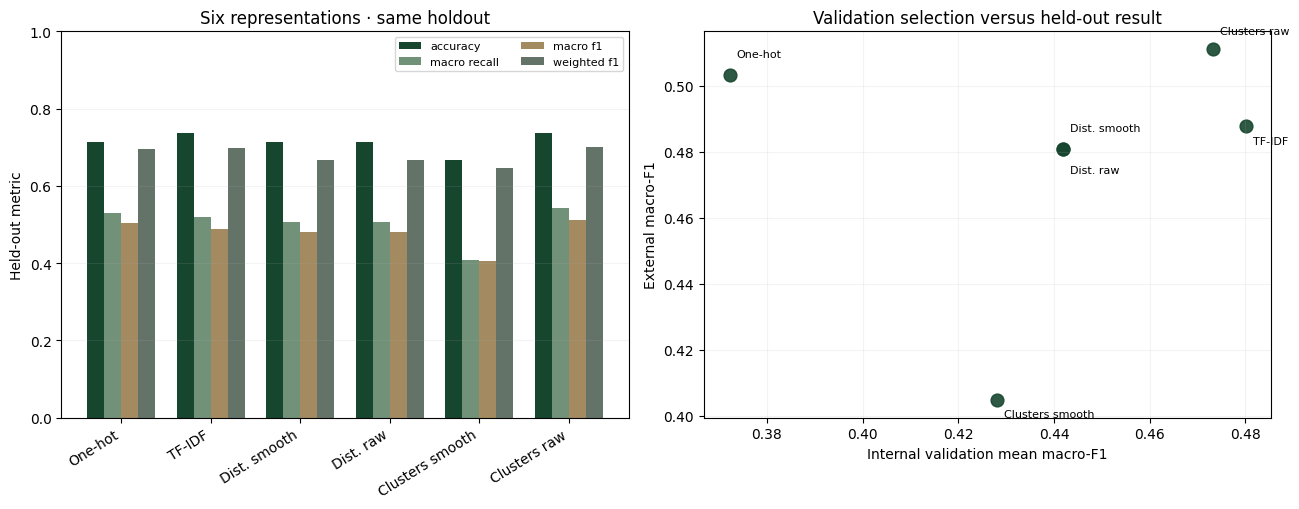

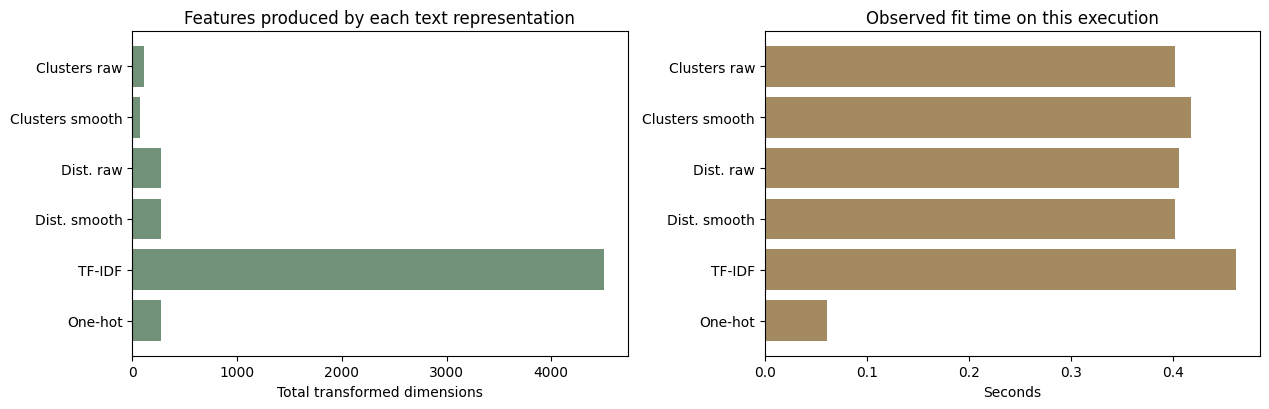

In [16]:
report_dir=Path(os.environ.get('CBS_V4_OUTPUT_DIR','v4_analysis_outputs'))
report_dir.mkdir(parents=True,exist_ok=True)
labels=['One-hot','TF-IDF','Dist. smooth','Dist. raw','Clusters smooth','Clusters raw']
metrics_to_plot=['accuracy','macro_recall','macro_f1','weighted_f1']
fig,axes=plt.subplots(1,2,figsize=(13.2,5.2))
ind=np.arange(len(labels));width=.19
for k,m in enumerate(metrics_to_plot):
    axes[0].bar(ind+(k-1.5)*width,external[m].to_numpy(),width,
        label=m.replace('_',' '),color=list(PALETTE.values())[[0,1,4,2][k]])
axes[0].set(ylim=(0,1),ylabel='Held-out metric',title='Six representations · same holdout')
axes[0].set_xticks(ind,labels,rotation=32,ha='right');axes[0].grid(axis='y',alpha=.14)
axes[0].legend(fontsize=8,ncol=2)
rank=inner_summary.set_index('model').loc[external.model]
axes[1].scatter(rank.macro_f1_mean.to_numpy(),external.macro_f1.to_numpy(),
                 color=PALETTE['blue'],s=85,alpha=.9)
# Two Euclidean variants can coincide: label both without implying distinct points.
annotation_offsets=[(5,13),(5,-13),(5,13),(5,-17),(5,-12),(5,11)]
for i,tag in enumerate(labels):
    axes[1].annotate(tag,(rank.macro_f1_mean.iloc[i],external.macro_f1.iloc[i]),
                     xytext=annotation_offsets[i],textcoords='offset points',fontsize=8)
axes[1].set(xlabel='Internal validation mean macro-F1',ylabel='External macro-F1',
            title='Validation selection versus held-out result')
axes[1].grid(alpha=.14)
fig.tight_layout();fig.savefig(report_dir/'v4_six_models_comparison.png',dpi=175,bbox_inches='tight')
plt.show()

fig,axs=plt.subplots(1,2,figsize=(12.8,4.2))
axs[0].barh(labels,external.n_features,color=PALETTE['teal'])
axs[0].set(title='Features produced by each text representation',xlabel='Total transformed dimensions')
axs[1].barh(labels,external.fit_sec,color=PALETTE['orange'])
axs[1].set(title='Observed fit time on this execution',xlabel='Seconds')
fig.tight_layout();fig.savefig(report_dir/'v4_feature_costs.png',dpi=165,bbox_inches='tight');plt.show()

## 17. מדדים לפי מחלקה, טעויות ושאלת המשמעות התפעולית

לא מחליפים precision ב-recall או ההפך. הדוח כולל כל מחלקה שהופיעה בנתוני הבדיקה או נחזתה, ואת תמיכת המחלקה (`support`). מספר תוויות הבדיקה שלא נצפו באימון הוא **מגבלה מבנית**, ולא שגיאה שאפשר לתקן בהנדסת טקסט בלבד.

Classification report: internally selected model / external holdout
              precision    recall  f1-score   support

        1212       0.00      0.00      0.00         1
        2120       0.00      0.00      0.00         0
        2330       0.00      0.00      0.00         1
        2342       1.00      1.00      1.00         1
        2412       0.00      0.00      0.00         1
        2511       0.00      0.00      0.00         2
        2512       0.00      0.00      0.00         0
        2514       0.33      1.00      0.50         1
        2631       1.00      1.00      1.00         1
        2635       1.00      1.00      1.00         1
        3122       1.00      1.00      1.00         2
        3312       0.00      0.00      0.00         1
        3323       0.00      0.00      0.00         2
        3334       0.00      0.00      0.00         1
        3512       0.00      0.00      0.00         1
        5120       1.00      1.00      1.00         4
        5131 

,occupation_code,precision,recall,f1-score,support
19,5223,0.857,1.0,0.923,6.0
15,5120,1.000,1.0,1.000,4.0
25,9112,1.000,1.0,1.000,4.0
21,5322,0.600,1.0,0.750,3.0
22,5412,1.000,1.0,1.000,3.0
5,2511,0.000,0.0,0.000,2.0
12,3323,0.000,0.0,0.000,2.0
10,3122,1.000,1.0,1.000,2.0
16,5131,1.000,1.0,1.000,2.0
0,1212,0.000,0.0,0.000,1.0


Disagreements: 11


,ID,actual,selected,seen_in_train,correct
3,25,3323,5322,False,False
15,88,3323,5322,False,False
25,139,1212,2120,False,False
26,140,2511,5142,True,False
27,144,3512,2512,True,False
32,166,2511,5142,True,False
33,174,2330,2514,False,False
35,177,5222,5230,False,False
36,180,3334,5223,False,False
38,184,2412,3512,False,False


Selected only correct: 2 | One-hot only correct: 1 | Both correct: 29


Paired bootstrap 95% interval, macro-F1 selected minus one-hot: [-0.075, 0.090]
Exploratory uncertainty only; not a production-population confidence interval.


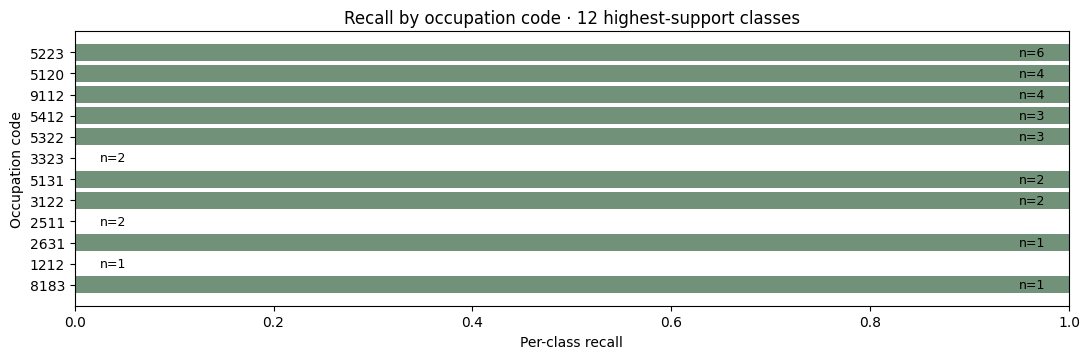

In [17]:
selected_pred=outer_predictions[SELECTED]
print('Classification report: internally selected model / external holdout')
print(classification_report(y_test,selected_pred,zero_division=0))
per_class=classification_report(y_test,selected_pred,zero_division=0,output_dict=True)
per_class_table=(pd.DataFrame(per_class).T.drop(index=['accuracy','macro avg','weighted avg'],errors='ignore')
                 .reset_index().rename(columns={'index':'occupation_code'}))
per_class_table['support']=pd.to_numeric(per_class_table.support)
display(per_class_table.sort_values(['support','recall'],ascending=[False,True]).head(30).round(3))

comparative_errors=pd.DataFrame({'ID':held_out.ID,'actual':held_out.given_code,
                                 'selected':selected_pred,
                                 'seen_in_train':held_out.class_seen_in_training})
comparative_errors['correct']=comparative_errors.actual.eq(comparative_errors.selected)
print('Disagreements:',int((~comparative_errors.correct).sum()))
display(comparative_errors.loc[~comparative_errors.correct].head(30))

# Paired holdout differences are diagnostic, not statistical proof on simulated labels.
base_pred=outer_predictions['One-hot: complete texts']
selected_correct=selected_pred==y_test.to_numpy()
base_correct=base_pred==y_test.to_numpy()
print('Selected only correct:',int(np.sum(selected_correct & ~base_correct)),
      '| One-hot only correct:',int(np.sum(base_correct & ~selected_correct)),
      '| Both correct:',int(np.sum(base_correct & selected_correct)))

# A small-sample paired bootstrap interval for the model-minus-one-hot macro-F1 difference.
rng=np.random.default_rng(SEED)
true=np.asarray(y_test,dtype=str)
boot=[]
for _ in range(800):
    sample=rng.integers(0,len(true),size=len(true))
    boot.append(f1_score(true[sample],selected_pred[sample],average='macro',zero_division=0)-
                f1_score(true[sample],base_pred[sample],average='macro',zero_division=0))
ci_low,ci_high=np.quantile(boot,[.025,.975])
print(f'Paired bootstrap 95% interval, macro-F1 selected minus one-hot: [{ci_low:.3f}, {ci_high:.3f}]')
print('Exploratory uncertainty only; not a production-population confidence interval.')

fig,ax=plt.subplots(figsize=(11,3.7))
important=per_class_table.sort_values('support',ascending=False).head(12).iloc[::-1]
ax.barh(important.occupation_code.astype(str),important.recall,color=PALETTE['teal'])
ax.set(xlim=(0,1),xlabel='Per-class recall',ylabel='Occupation code',
       title='Recall by occupation code · 12 highest-support classes')
for i,(_,row) in enumerate(important.iterrows()):
    ax.text(min(float(row.recall)+.025,.95),i,f'n={int(row.support)}',fontsize=9,va='center')
fig.tight_layout();fig.savefig(report_dir/'v4_per_class_recall.png',dpi=175,bbox_inches='tight')
plt.show()

## 18. עקומות Calinski–Harabasz והכרעות K

לכל גרסת KMeans מציגים את כל המועמדים `K` שנבחנו ואת הניקוד שלהם; בחירה ב-CH נועדה למצוא חלוקה עם יחס פיזור בין-אשכולי גבוה ביחס לפיזור תוך-אשכולי. **הניקוד אינו מדד רלוונטיות או זהות סמנטית של משלחי יד**. בנוסף לסכימת CH אנו בוחנים את תוכן האשכולות בפועל.

,field,smoothing,n_distinct_values,chosen_k,ch_score
0,SugAvoda,True,64,4,2.0861
1,ShemMachlaka,True,50,9,1.4400
2,SugMachlaka,True,27,2,1.6084
3,EzoAvoda,True,67,16,1.9807
4,TeurPeula,True,24,15,1.5696
5,TeurTafkid,True,10,2,1.1517
6,SugAvoda,False,64,20,1.8752
7,ShemMachlaka,False,50,13,1.3769
8,SugMachlaka,False,27,18,1.4582
9,EzoAvoda,False,67,19,1.9452


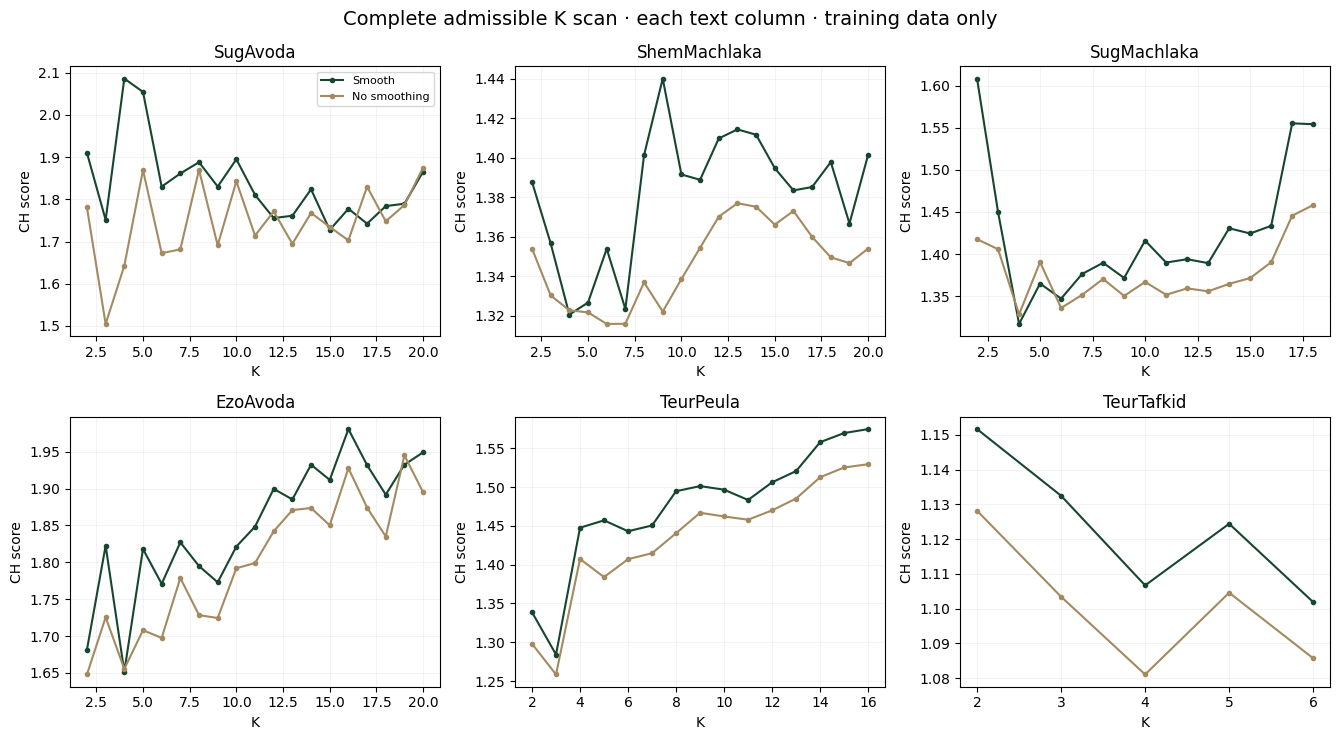

In [18]:
all_curves=[];selected_k=[]
for key,smoothing in [('CH clusters → one-hot · smooth',True),
                      ('CH clusters → one-hot · no smooth',False)]:
    branch=(outer_models[key].named_steps['represent'].named_transformers_['cluster_text'])
    classifier_encoder=branch.named_steps['onehot']
    cluster=branch.named_steps['assign']
    raw_clusters=cluster.transform(X_test[APPROVED_TEXT])
    cluster_ohe=classifier_encoder.transform(raw_clusters)
    nonzeros=cluster_ohe.toarray() if hasattr(cluster_ohe,'toarray') else np.asarray(cluster_ohe)
    assert set(np.unique(nonzeros)).issubset({0,1})
    assert raw_clusters.dtype==object
    a=cluster.score_table_.copy();a['representation']=key
    b=cluster.selection_table_.copy();b['representation']=key
    all_curves.append(a);selected_k.append(b)
ch_curves=pd.concat(all_curves,ignore_index=True)
k_selected=pd.concat(selected_k,ignore_index=True)
display(k_selected[['field','smoothing','n_distinct_values','chosen_k','ch_score']].round(4))
fig,axes=plt.subplots(2,3,figsize=(13.5,7.5))
for ax,field in zip(axes.flat,APPROVED_TEXT):
    for smooth,c,lab in [(True,PALETTE['blue'],'Smooth'),
                         (False,PALETTE['orange'],'No smoothing')]:
        subset=ch_curves.loc[ch_curves.field.eq(field)&ch_curves.smoothing.eq(smooth)]
        if len(subset):ax.plot(subset.k,subset.ch,'o-',label=lab,color=c,markersize=3)
    ax.set(title=field,xlabel='K',ylabel='CH score')
    ax.grid(alpha=.15)
axes.flat[0].legend(fontsize=8)
fig.suptitle('Complete admissible K scan · each text column · training data only',fontsize=14)
fig.tight_layout();fig.savefig(report_dir/'v4_ch_curves.png',dpi=175,bbox_inches='tight')
plt.show()

## 19. בדיקה מקצועית של חברי אשכול — דוגמאות שקשורות לפיתוח תוכנה

מדידת דמיון לקסיקלי אינה שקולה לשיפוט מקצועי. בדיקה זו מדפיסה לכל אחת משתי הגרסאות את **חברי אשכולות האימון בפועל**, כאשר הערכים מכילים ביטויים כגון ״תוכנה״, ״מתכנת״ או ״פיתוח״. אין לפסוק מראש שערכים שונים צריכים או לא צריכים להתאחד; יש להראות לקורא מה קרה ולדון בשגיאות עם סמלנים.

In [19]:
software_pattern=r'תוכנ|מתכנת|מפתח|פיתוח'
review_members=[]
for model_key in ['CH clusters → one-hot · smooth','CH clusters → one-hot · no smooth']:
    cluster=(outer_models[model_key].named_steps['represent']
             .named_transformers_['cluster_text'].named_steps['assign'])
    for field in APPROVED_TEXT:
        for val,cid in cluster.models_[field]['lookup'].items():
            if re.search(software_pattern,val,flags=re.IGNORECASE):
                review_members.append({'model':model_key,'field':field,'observed_description':val,
                                       'cluster':cid})
member_audit=pd.DataFrame(review_members,columns=['model','field','observed_description','cluster'])
print('Training descriptions matching the software audit terms:',len(member_audit))
for field in ['EzoAvoda','SugAvoda','TeurTafkid']:
    print('---',field,'---')
    display(member_audit.loc[member_audit.field.eq(field)].head(25))
if len(member_audit):
    for model_key in member_audit.model.unique():
        print(model_key,'| distinct clusters in identified software terms:',
              int(member_audit.loc[member_audit.model.eq(model_key),'cluster'].nunique()))

Training descriptions matching the software audit terms: 42
--- EzoAvoda ---


,model,field,observed_description,cluster
9,CH clusters → one-hot · smooth,EzoAvoda,"מהנדס תוכנה, מנהל צוות עובדים",cluster_004
10,CH clusters → one-hot · smooth,EzoAvoda,"מהנדס תוכנה, מנהל צוות פיתוח",cluster_004
11,CH clusters → one-hot · smooth,EzoAvoda,מנהל פיתוח,cluster_004
12,CH clusters → one-hot · smooth,EzoAvoda,מפתח,cluster_013
13,CH clusters → one-hot · smooth,EzoAvoda,מפתח אפליקציות,cluster_013
14,CH clusters → one-hot · smooth,EzoAvoda,מפתח תוכנה,cluster_013
15,CH clusters → one-hot · smooth,EzoAvoda,מתכנת,cluster_012
16,CH clusters → one-hot · smooth,EzoAvoda,"ר""ש פיתוח",cluster_004
30,CH clusters → one-hot · no smooth,EzoAvoda,"מהנדס תוכנה, מנהל צוות עובדים",cluster_009
31,CH clusters → one-hot · no smooth,EzoAvoda,"מהנדס תוכנה, מנהל צוות פיתוח",cluster_009


--- SugAvoda ---


,model,field,observed_description,cluster
0,CH clusters → one-hot · smooth,SugAvoda,"הייטק, פיתוח תוכנה",cluster_000
1,CH clusters → one-hot · smooth,SugAvoda,מנהל פיתוח,cluster_000
2,CH clusters → one-hot · smooth,SugAvoda,פיתוח מוצרי תוכנה,cluster_000
3,CH clusters → one-hot · smooth,SugAvoda,פיתוח תוכנה,cluster_000
4,CH clusters → one-hot · smooth,SugAvoda,פיתוח תוכנה לצ'יפים,cluster_000
5,CH clusters → one-hot · smooth,SugAvoda,פיתוח תכנה,cluster_000
21,CH clusters → one-hot · no smooth,SugAvoda,"הייטק, פיתוח תוכנה",cluster_001
22,CH clusters → one-hot · no smooth,SugAvoda,מנהל פיתוח,cluster_001
23,CH clusters → one-hot · no smooth,SugAvoda,פיתוח מוצרי תוכנה,cluster_001
24,CH clusters → one-hot · no smooth,SugAvoda,פיתוח תוכנה,cluster_001


--- TeurTafkid ---


,model,field,observed_description,cluster
20,CH clusters → one-hot · smooth,TeurTafkid,פיתוח תכנה,cluster_000
41,CH clusters → one-hot · no smooth,TeurTafkid,פיתוח תכנה,cluster_000


CH clusters → one-hot · smooth | distinct clusters in identified software terms: 7
CH clusters → one-hot · no smooth | distinct clusters in identified software terms: 9


## 20. הצעות לקודים חלקיים — שלב סקירה אנושית

לא משתמשים בתוויות הכוללות `X` באימון או במדדי השוואה. לאחר ההכרעה מראש וביצוע המבחן, מתאיםים את השיטה שנבחרה **מחדש על כל 191 הרשומות בעלות הסימול המלא** ומציעים סמלים עבור 9 הרשומות החלקיות. ההצעה אינה החלפה אוטומטית, והסתברויות לא מכוילות אינן מוגדרות אמון תפעולי.

In [20]:
selected_kind,_,selected_smooth=next((k,name,s) for k,name,s in VARIANTS if name==SELECTED)
review_fit=build_candidate(selected_kind,selected_smooth).fit(X,y)
review_proposals=review_fit.predict(model_features(partial))
review_table=pd.DataFrame({'ID':partial['ID'].astype(int).to_numpy(),
                           'partially_coded_original':partial[TARGET].astype(str).to_numpy(),
                           'suggested_complete_code':review_proposals,
                           'operational_status':'human_coder_review'})
assert len(review_table)==9
print('Suggestions generated by internally selected representation, refitted on all full labels:')
display(review_table)
print('Source workbook unchanged. These are model suggestions, not verified occupation codes.')

Suggestions generated by internally selected representation, refitted on all full labels:


,ID,partially_coded_original,suggested_complete_code,operational_status
0,18,1XXX,2511,human_coder_review
1,45,XXXX,2511,human_coder_review
2,50,1XXX,2511,human_coder_review
3,81,1XXX,2511,human_coder_review
4,108,XXXX,2511,human_coder_review
5,113,1XXX,2511,human_coder_review
6,142,XXXX,5223,human_coder_review
7,165,335X,3354,human_coder_review
8,193,XXXX,5223,human_coder_review


Source workbook unchanged. These are model suggestions, not verified occupation codes.


## 21. מסקנה מהשוואת השיטות ומסלול הטמעה מעשי

1. **כיצד נקבעה העדיפות?** `macro_F1` ממוצע באימות פנימי מקובץ, לפני מבחן-החוץ. השורה הנבחרת מסומנת ללא התחשבות בנתוני הבדיקה החיצונית. אין לכנות שיפור קטן על מדגם דמה ״שיפור מובהק״.
2. **מה קידום בוצע?** השוואה בין ייצוג נומינלי מקורי, מידע תווי משוקלל, מרחק אוקלידי מפורש וצבירה לא-מונחית לקודים נומינליים; בדיקת שני ערכי `smooth_idf`; CH מלא על טווח K שהוגדר מראש; סקירת חברי אשכול ומחלקות יעד נדירות.
3. **מה בלתי-פתיר מהנתונים שסופקו?** חסר מזהה נסקר יציב על פני שידורים חוזרים, אין תאריך שידור, אין ״תוויות זהב״ מאומתות, והסמל הענפי הסופי עשוי להיות לא זמין בזמן הסיווג. יש מחלקות נדירות ובלתי-נראות באימון; המידע אינו מספיק להסקת דיוק מערכתי.
4. **המשך הטמעה אחראי:** נתוני אמת עם קישור לשידורים וגרסאות, מדגם תיוג מקצועי עצמאי, בדיקת תאריכים ומשתתפים ללא זליגה, ניטור שגיאות לפי מקצוע, טיפול במקרים לא מזוהים, סקרי עקביות בין סמלנים, ובחינת שימוש הדרגתי ב־human-in-the-loop.

### מקורות מקצועיים (תיעוד רשמי)
- [scikit-learn — Text clustering by KMeans](https://scikit-learn.org/stable/auto_examples/text/plot_document_clustering.html)
- [TfidfVectorizer — L2 and smooth_idf](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html)
- [Euclidean distances](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.euclidean_distances.html)
- [Calinski–Harabasz score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.calinski_harabasz_score.html)
- [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
- [Common pitfalls and leakage](https://scikit-learn.org/stable/common_pitfalls.html)
- [GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html)
- [Classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html)

**עיצוב:** פלטה בהשראת צילום המסך השמור של תיק העבודות, ולא תיעוד CSS שאומת מן האתר החי. האיורים והממצאים מוצגים על בסיס נתוני המטלה בלבד.

In [21]:
# Final reproducibility and handoff: all comparisons are saved as human-readable data.
import json
results_record={
 'source_sha256':actual_hash,'python_version':sys.version.split()[0],
 'pandas_version':pd.__version__,'sklearn_version':sklearn.__version__,
 'train_rows':len(X_train),'holdout_rows':len(X_test),
 'unseen_holdout_labels':int((~y_test.isin(set(y_train))).sum()),
 'selected_on_inner_validation':SELECTED,
 'inner_models':inner_summary[['model','macro_f1_mean','macro_recall_mean',
                               'weighted_f1_mean','accuracy_mean']].to_dict('records'),
 'outer_models':external[['model','correct','accuracy','macro_recall',
                           'macro_f1','weighted_f1']].to_dict('records'),
 'bootstrap_selected_vs_onehot_macro_f1':[float(ci_low),float(ci_high)],
 'cluster_k':k_selected.replace({np.nan:None}).to_dict('records'),
 'limitations':['simulated data','manual-label uncertainty',
                'participant linkage unavailable','novel occupation codes'],
}
(report_dir/'v4_results.json').write_text(
    json.dumps(results_record,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
external.to_csv(report_dir/'v4_external_models.csv',index=False,encoding='utf-8-sig')
inner_results.to_csv(report_dir/'v4_inner_validation.csv',index=False,encoding='utf-8-sig')
held_out.to_csv(report_dir/'v4_holdout_predictions.csv',index=False,encoding='utf-8-sig')
review_table.to_csv(report_dir/'v4_partial_code_review.csv',index=False,encoding='utf-8-sig')
print('REPORT COMPLETE | Internally selected model:',SELECTED)
print('All 18 columns audited | Six methods evaluated | Raw dataset unchanged')
print('CH choices, complete K curves, held-out predictions and findings available in',report_dir)

REPORT COMPLETE | Internally selected model: Direct TF-IDF · smooth
All 18 columns audited | Six methods evaluated | Raw dataset unchanged
CH choices, complete K curves, held-out predictions and findings available in /mnt/data/_v4_report_assets


## Multiclass soft-voting classification
The experiment compares individually optimized classifiers with separately fitted default-parameter and optimized-parameter soft-voting ensembles. All models predict nominal occupation-code labels.

In [ ]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from scipy.sparse import issparse
import numpy as np

class CatBoostMulticlassAdapter(ClassifierMixin, BaseEstimator):
    def __init__(self, iterations=1000, depth=6, learning_rate=None, l2_leaf_reg=3, random_strength=1, random_seed=42):
        self.iterations = iterations
        self.depth = depth
        self.learning_rate = learning_rate
        self.l2_leaf_reg = l2_leaf_reg
        self.random_strength = random_strength
        self.random_seed = random_seed

    def fit(self, training_features, training_labels):
        self.classes_ = np.unique(training_labels)
        parameters = dict(iterations=self.iterations, depth=self.depth, l2_leaf_reg=self.l2_leaf_reg, random_strength=self.random_strength, random_seed=self.random_seed, loss_function="MultiClass", verbose=False, thread_count=1, allow_writing_files=False)

        if self.learning_rate is not None:
            parameters["learning_rate"] = self.learning_rate

        self.fitted_classifier_ = CatBoostClassifier(**parameters)
        training_matrix = training_features.toarray() if issparse(training_features) else training_features
        self.fitted_classifier_.fit(training_matrix, training_labels)
        return self

    def predict_proba(self, prediction_features):
        prediction_matrix = prediction_features.toarray() if issparse(prediction_features) else prediction_features
        return self.fitted_classifier_.predict_proba(prediction_matrix)

    def predict(self, prediction_features):
        return self.classes_[np.argmax(self.predict_proba(prediction_features), axis=1)]


def create_default_soft_voting_classifier():
    return VotingClassifier(estimators=[
        ("random_forest", RandomForestClassifier(random_state=42, n_jobs=1)),
        ("xgboost", XGBClassifier(random_state=42, n_jobs=1, verbosity=0)),
        ("lightgbm", LGBMClassifier(random_state=42, n_jobs=1, verbosity=-1)),
        ("catboost", CatBoostMulticlassAdapter(random_seed=42)),
        ("logistic", LogisticRegression(max_iter=1000, random_state=42)),
    ], voting="soft", n_jobs=1)


def create_optimized_soft_voting_classifier(selected_parameters):
    return VotingClassifier(estimators=[
        ("random_forest", RandomForestClassifier(**selected_parameters["RandomForestClassifier"], random_state=42, n_jobs=1)),
        ("xgboost", XGBClassifier(**selected_parameters["XGBClassifier"], random_state=42, n_jobs=1, verbosity=0)),
        ("lightgbm", LGBMClassifier(**selected_parameters["LGBMClassifier"], random_state=42, n_jobs=1, verbosity=-1)),
        ("catboost", CatBoostMulticlassAdapter(**selected_parameters["CatBoostClassifier"], random_seed=42)),
        ("logistic", LogisticRegression(**selected_parameters["LogisticRegression"], max_iter=1000, random_state=42)),
    ], voting="soft", n_jobs=1)
